# Notebook for Case 3

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
from sampler.reader import ObservationReader, ReflectionReader

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams.update({
    "font.family": "serif"
})

## Set up observation and reflections

In [2]:
data_path = '../simulated_data/case_3'

observation = ObservationReader(f'{data_path}/sim_data.hdf5')
print(np.unique(observation.states_array))

reflection_dict = {'antenna':f'{data_path}/antenna_gamma_src.s2p',
                   'heated_load':f'{data_path}/heated_load_gamma_src.s2p',
                   'internal_load':f'{data_path}/internal_load_gamma_src.s2p',
                   'long_open':f'{data_path}/long_open_gamma_src.s2p',
                   'long_short':f'{data_path}/long_short_gamma_src.s2p',
                   'open':f'{data_path}/open_gamma_src.s2p',
                   'short':f'{data_path}/short_gamma_src.s2p',
                   'receiver':f'{data_path}/gamma_rec.s2p',
                   'noise_diode':f'{data_path}/noise_diode_gamma_src.s2p'}

reflections = ReflectionReader(component_dict=reflection_dict,
                               output_frequencies=observation.freqs,
                               polynomial_interp=True,
                               polynomial_fitting_order=10)



Calculated... delta_nu: 19531.25, delta_t: 5.0
['antenna' 'heated_load' 'internal_load' 'long_open' 'long_short' 'open'
 'short']


/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be poorly conditioned
  polyfit = np.polyfit(x=freq,
/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be poorly conditioned
  polyfit = np.polyfit(x=freq,
/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be poorly conditioned
  polyfit = np.polyfit(x=freq,
/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be poorly conditioned
  polyfit = np.polyfit(x=freq,
/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be poorly conditioned
  polyfit = np.polyfit(x=freq,
/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be poorly conditioned
  polyfit = np.polyfit(x=freq,
/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/reader.py:158: RankWarning: Polyfit may be 

# Check Observation

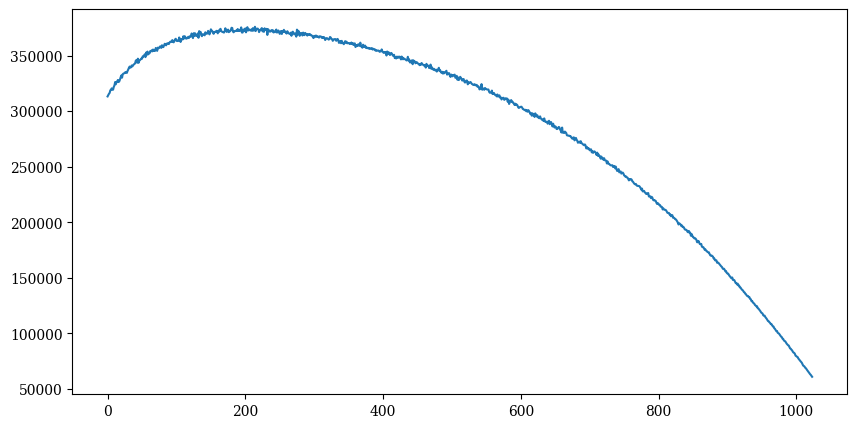

In [3]:
plt.plot(observation.data_waterfall[100])
plt.show()

# RFI Flag

In [4]:
from MomentRFI.MomentRFI import IterativeSurfaceFitter
from rfi_flagging.rfi_flagging import mask_by_state


## Set up basis functions

In [5]:
from sampler.linear_basis import BasisConstructor

In [6]:

gains_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=5,
                            n_freq_modes=5,
                            basis_function='legendre',
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

unc_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=5,
                            n_freq_modes=5,
                            basis_function='legendre',
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

cos_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=5,
                            n_freq_modes=5,
                            basis_function='legendre',
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

sin_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=5,
                            n_freq_modes=5,
                            basis_function='legendre',
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

rx_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=5,
                            n_freq_modes=5,
                            basis_function='legendre',
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)


# Set up thermal bases
# cal temperature set up: give the same time orders
cal_n_time_modes = 6


ambient_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=cal_n_time_modes,
                            n_freq_modes=1,
                            basis_function='polynomial',
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

ambient_basis_y = BasisConstructor(observation.times,
                            0,
                            n_time_modes=cal_n_time_modes,
                            n_freq_modes=1,
                            basis_function='polynomial',
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

heated_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=cal_n_time_modes,
                            n_freq_modes=1,
                            basis_function='polynomial',
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

heated_basis_y = BasisConstructor(observation.times,
                            0,
                            n_time_modes=cal_n_time_modes,
                            n_freq_modes=1,
                            basis_function='polynomial',
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)
####

antenna_basis = BasisConstructor(observation.times,
                            observation.freqs,
                            n_time_modes=1,
                            n_freq_modes=1,
                            basis_function='polynomial',
                            time_norm=1*(observation.times[-1] - observation.times[0]),
                            frequency_norm=np.median(observation.freqs),
                            zero_time=True)

/Users/user/Desktop/RHINO/rhino-cal/notebooks/../sampler/linear_basis.py:246: RuntimeWarning: invalid value encountered in scalar divide
  return 2.0 * (array - array_min) / (array_max - array_min) - 1.0


## Construct Operators

In [7]:
from sampler.operator_setup import generate_noise_wave_transfer_matrix
from sampler.operator_setup import generate_non_smooth_source_matrix, generate_smooth_source_matrix, generate_noise_wave_transfer_matrix
# Noise Wave Operator
X_noise_wave, nw_slice_dict = generate_noise_wave_transfer_matrix(observation,
                                                               reflections,
                                                               unc_basis,
                                                               cos_basis,
                                                               sin_basis,
                                                               rx_basis)
print(nw_slice_dict)
print(X_noise_wave.shape)


{'unc': slice(0, 25, None), 'cos': slice(25, 50, None), 'sin': slice(50, 75, None), 'rx': slice(75, 100, None)}
(4423680, 100)


## Construct Antenna Operator

In [8]:
X_antenna = generate_smooth_source_matrix(observation,
                                          reflections,
                                          source_basis=antenna_basis,
                                          source_label='antenna')

# X_noise_diode = generate_smooth_source_matrix(observation,
#                                           reflections,
#                                           source_basis=noise_diode_basis,
#                                           source_label='noise_diode')

print(X_antenna.shape)

(4423680, 1)


### Combine Noisewave and Antenna Operators

In [9]:
from sampler.operator_setup import concat_and_index_operators

X_ant_noisewave = np.concatenate((X_antenna, X_noise_wave), axis=1)

X_ant_noisewave, ant_noise_wave_slice_dict = concat_and_index_operators([X_antenna,
                                                                         #X_noise_diode,
                                                                         X_noise_wave],
                                                                         label_list=['antenna',
                                                                                     #'noise_diode',
                                                                                     'noise_wave'])

print(ant_noise_wave_slice_dict)

{'antenna': slice(0, 1, None), 'noise_wave': slice(1, 101, None)}


## Construct Calibration Source Operator

In [10]:
print(np.unique(observation.switch_states))

['antenna' 'heated_load' 'internal_load' 'long_open' 'long_short' 'open'
 'short']


In [11]:
X_ambient = generate_smooth_source_matrix(observation, reflections,
                                          source_basis=ambient_basis,
                                          source_label=['internal_load', 'long_open',
                                                        'long_short', 'open', 'short'])
X_heated = generate_smooth_source_matrix(observation, reflections,
                                         source_basis=heated_basis,
                                         source_label='heated_load')

X_calibrator, calibrator_slice_dict = concat_and_index_operators([X_ambient,
                                                                  X_heated],
                                                                  ['ambient',
                                                                   'heated'])


from sampler.priors import generate_smooth_thermistor_operator_matrix

Y_ambient = generate_smooth_thermistor_operator_matrix(observation,
                                          source_basis=ambient_basis_y,
                                          source_label=['internal_load', 'long_open',
                                                        'long_short', 'open', 'short'])


Y_heated = generate_smooth_thermistor_operator_matrix(observation,
                                         source_basis=heated_basis_y,
                                         source_label='heated_load')

Y_calibrator, calibrator_slice_dict_y = concat_and_index_operators([Y_ambient,
                                                                  Y_heated],
                                                                  ['ambient',
                                                                   'heated'])

In [12]:

# plt.pcolormesh(X_calibrator)
# plt.show()

# plt.pcolormesh(Y_calibrator)
# plt.show()

print(calibrator_slice_dict)

cont = X_calibrator @ np.ones_like(X_calibrator[0])
cont = np.reshape(cont, shape=observation.data_waterfall.shape)
# plt.pcolormesh(cont)
# plt.show()

{'ambient': slice(0, 6, None), 'heated': slice(6, 12, None)}


In [13]:
print(np.unique(observation.switch_states))

['antenna' 'heated_load' 'internal_load' 'long_open' 'long_short' 'open'
 'short']


### Construct Cal Source Priors

In [14]:
from sampler.priors import setup_probe_cal_priors
cal_source_priors, cal_source_prior_inv_cov = setup_probe_cal_priors(observation,
                                           source_temp_dict={'heated':'heated_load',
                                                             'ambient':['internal_load',
                                                                        'open',
                                                                        'short',
                                                                        'long_open',
                                                                        'long_short']},
                                                                        temp_std=0.01)


In [15]:
### Attempt a Weiner solution fit

from sampler.gibbs_sample import construct_gcr_lhs, construct_gcr_rhs, solve_gcr



cal_source_lhs = construct_gcr_lhs(linear_operator=Y_calibrator,
                                   inv_data_cov=cal_source_prior_inv_cov,
                                   inv_prior_cov=None,)
cal_source_rhs = construct_gcr_rhs(linear_operator=Y_calibrator,
                                   data=cal_source_priors,
                                   inv_data_cov=cal_source_prior_inv_cov,
                                   omega_data=np.zeros_like(cal_source_priors),
                                   priors=None,
                                   inv_prior_cov=None,
                                   weiner_solution=True,)

init_calibrator_solution = solve_gcr(cal_source_lhs, cal_source_rhs,linalg_init=False,
                                     atol=1e-10, rtol=1e-12, maxiter=int(1e6))


print(init_calibrator_solution)


# ambient_amps, heated_amps = init_calibrator_solution[:4], init_calibrator_solution[4:]
# print(ambient_amps)
# print(heated_amps)

# reconstructed_ambient = ambient_basis.basis_matrix @ ambient_amps
# reconstructed_heated = ambient_basis.basis_matrix @ heated_amps

# plt.pcolormesh(np.reshape(reconstructed_ambient, shape=observation.data_waterfall.shape))
# plt.colorbar()
# plt.show()

# plt.pcolormesh(np.reshape(reconstructed_heated, shape=observation.data_waterfall.shape))
# plt.colorbar()
# plt.show()

[ 1.46424265e-02  1.05018599e-02  8.70710283e+00  2.30209241e+00
 -8.03869622e+00  2.91844854e+02 -3.54721695e-03  1.02272424e-03
 -2.55874959e+00  7.88746033e-01  1.97524188e+00  3.92605526e+02]


In [16]:
# cal_source_priors = np.array([np.mean(observation.temperatures['ambient']),
#                                      np.mean(observation.temperatures['heated'])])
# cal_source_prior_inv_cov = np.ones_like(cal_source_priors) * (1 / 0.0005)

print(cal_source_prior_inv_cov)

[    0.     0.     0. ... 10000. 10000. 10000.]


In [17]:
## Construct cal source priors from raw temperatures

## Gain Operator

In [18]:
U_gain = gains_basis.basis_matrix
print(U_gain.shape)
# plt.pcolormesh(U_gain)
# plt.show()

(4423680, 25)


In [19]:
print(observation.temperatures)

{'heated': array([393.97333203, 393.9633801 , 393.94936465, ..., 392.80559394,
       392.79887   , 392.82791814], shape=(4320,)), 'ambient': array([293.46728335, 293.48392571, 293.47912184, ..., 294.80151109,
       294.79483942, 294.82802203], shape=(4320,))}


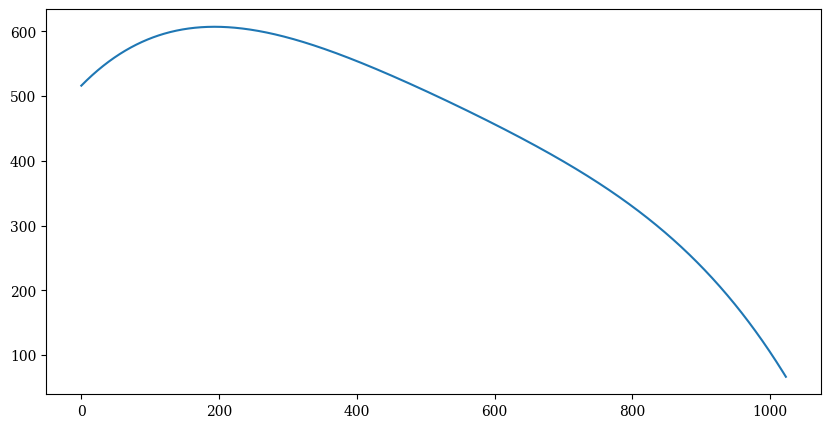

In [20]:
# get an initial guess of the gains params

def init_gain_guess(observation_obj: ObservationReader,
                    reflections_obj: ReflectionReader,
                    gains_basis: BasisConstructor,
                    noise_source_label: str = "heated_load",
                    load_label: str = 'internal_load',
                    noise_source_temp: int | None = None):

    noise_source_mask = (observation_obj.states_array == noise_source_label)
    load_mask = (observation_obj.states_array == load_label)
    p_ns = observation_obj.data_waterfall[noise_source_mask].mean(axis=0)
    p_l = observation_obj.data_waterfall[load_mask].mean(axis=0)

    if noise_source_temp is not None: t_ns = noise_source_temp
    else:
        t_ns = np.mean(observation_obj.temperatures['heated'])
    t_l = np.mean(observation_obj.temperatures['ambient'])

    gamma_rec = reflections_obj.s11_dict['receiver']

    mean_gain = (p_ns - p_l) / ((t_ns - t_l) * (1 - np.power(np.abs(gamma_rec), 2)))

    fitting_gain = np.zeros_like(observation.data_waterfall)
    fitting_gain[:,:] = mean_gain
    fitting_gain = fitting_gain.flatten()
    init_amp_guess = np.linalg.lstsq(gains_basis.basis_matrix, fitting_gain)[0]

    return init_amp_guess


# def gain_correction(observation_obj: ObservationReader,
#                     reflections_obj: ReflectionReader,
#                     noise_source_label: str = "heated_load",
#                     load_label: str = 'internal_load',
#                     polynomial_order: int,
#                     noise_source_temp: int | None = None,):
    
#     noise_source_mask = (observation_obj.states_array == noise_source_label)
#     load_mask = (observation_obj.states_array == load_label)
#     p_ns = observation_obj.data_waterfall[noise_source_mask].mean(axis=0)
#     p_l = observation_obj.data_waterfall[load_mask].mean(axis=0)
    


init_gain_amps = init_gain_guess(observation, reflections, gains_basis)

recov_init_gains = gains_basis.basis_matrix @ init_gain_amps
recov_init_gains = np.reshape(recov_init_gains,
                              shape=observation.data_waterfall.shape)

plt.plot(np.mean(recov_init_gains, axis=0))

# Set up Gibbs Sampler

In [21]:
# from sampler.gibbs_sample import sample_loop
from sampler.gibbs_sample import GibbsSampleParams

In [22]:
print(init_calibrator_solution)

[ 9.07114475e-03 -7.30018428e-03 -8.34856931e+00 -6.47642444e+00
  6.00197164e+00  2.96241474e+02  4.67374645e-03 -8.28350729e-03
 -3.93036802e+00  6.16444015e+00  3.92403295e+00  3.89920596e+02]


In [23]:
print()

In [24]:
# param_dict = sample_loop(data=observation.data_waterfall.flatten(),
#                          N=observation.Nw.flatten(),
#                          U_gain=U_gain,
#                          X_ant_nw=X_ant_noisewave,
#                          X_cal_src=X_calibrator,
#                          init_gain_amps=init_gain_amps,
#                          init_cal_src_amps=init_calibrator_solution,
#                          init_ant_nw_amps=np.ones_like(X_ant_noisewave[0]),
#                          cal_src_priors=cal_source_priors,
#                          inv_cal_src_prior_cov=cal_source_prior_inv_cov, n_iter=500,
#                          fix_cal_source=False,
#                          Y_cal_src=Y_calibrator,
#                          verbose=False,
#                          chi_square_interval=100)

param_dict = GibbsSampleParams(
    data=observation.data_waterfall.flatten(),
                         N=observation.Nw.flatten(),
                         U_gain=U_gain,
                         X_ant_nw=X_ant_noisewave,
                         X_cal_src=X_calibrator,
                         init_gain_amps=init_gain_amps,
                         init_cal_src_amps=init_calibrator_solution,
                         init_ant_nw_amps=np.ones_like(X_ant_noisewave[0]),
                         cal_src_priors=cal_source_priors,
                         inv_cal_src_prior_cov=cal_source_prior_inv_cov, n_iter=750,
                         Y_cal_src=Y_calibrator,
                         verbose=True,
                         chi_square_interval=100
)

python(55097) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Gibbs Sampling:   0%|          | 0/750 [00:00<?, ?it/s]

d_cont  [340.16748778 340.27623857 341.08121052 ... 137.06505629 134.5199753
 137.01812653]
inv_cont_cov  [2.54312206 2.4732749  2.40756063 ... 0.62212681 0.62139689 0.62067639]
d_gain  [313.95755598 317.34705106 321.41364151 ...  89.83641036  88.6762671
  88.4148662 ]
d_gain_inv_cov  [ 1.5031822   1.43255661  1.36770996 ... 12.04754517 12.3315434
 12.62594216]
d_cont  [ 63.24238827  58.65866212  55.42833802 ... 369.57778002 368.73400544
 374.03091569]
inv_cont_cov  [0.51389804 0.51909507 0.5243835  ... 0.8460739  0.85022626 0.85444453]


Gibbs Sampling:   0%|          | 1/750 [00:12<2:42:09, 12.99s/it]

chi_sq:  1563062350544566.8
d_cont  [499.16715284 492.39576093 486.97276402 ... 241.77565928 240.29905293
 244.96121023]
inv_cont_cov  [3.12103486 3.0568029  2.99634539 ... 1.1829995  1.18352232 1.18407441]
d_gain  [-82.17847402 -84.04492177 -86.15054234 ... 112.92167355 111.76143451
 111.73188795]
d_gain_inv_cov  [2.02919426e+02 2.29363850e+02 2.61103357e+02 ... 1.60167396e-01
 1.48263502e-01 1.37415247e-01]
d_cont  [1805.90788793 1827.01260448 1880.81248248 ...  -92.70408102  -91.67749691
  -90.42849841]
inv_cont_cov  [0.0352088  0.03640834 0.03767354 ... 0.18205677 0.18131228 0.18057452]


Gibbs Sampling:   0%|          | 2/750 [00:29<3:09:51, 15.23s/it]

d_cont  [140.48546069 189.25524399 270.79051795 ... 904.10195819 902.89487632
 901.89592406]
inv_cont_cov  [0.00068876 0.00069834 0.00070826 ... 0.00602251 0.00591224 0.00580431]
d_gain  [-11.06261214 -11.28741883 -11.54190631 ... -10.44862628 -10.15604154
  -9.97187558]
d_gain_inv_cov  [5.50785872e-05 5.66921163e-05 5.83601404e-05 ... 1.72578572e-01
 1.57730810e-01 1.44515234e-01]
d_cont  [12371.19270829 12194.18331224 12017.05621218 ...  4243.88883958
  4316.60610666  4389.76593716]
inv_cont_cov  [0.00063804 0.0006567  0.0006762  ... 0.0013107  0.00128968 0.001269  ]


... (14 outputs left out)

Gibbs Sampling:   1%|▏         | 10/750 [02:17<2:44:57, 13.38s/it]

d_cont  [-794.00137033 -829.2175885  -868.46131112 ...  635.20160884  671.12977478
  699.01305248]
inv_cont_cov  [2.57281206e-05 1.32430316e-04 1.91086804e-03 ... 1.12359097e-07
 1.08848044e-07 1.05475424e-07]
d_gain  [0.00894206 0.00909158 0.00926377 ... 0.10788522 0.10377177 0.10085917]
d_gain_inv_cov  [2441.69803611 2419.55319509 2399.56974411 ...  188.31287963  180.92246075
  173.891216  ]
d_cont  [-15306365.60650194 -15140821.2258325  -14973746.35576188 ...
   -498810.92811096   -511043.80930221   -523381.54744353]
inv_cont_cov  [4.16879065e-10 4.26046353e-10 4.35608554e-10 ... 3.14706779e-07
 3.01348175e-07 2.88720184e-07]


Gibbs Sampling:   1%|▏         | 11/750 [02:42<3:02:19, 14.80s/it]


KeyboardInterrupt: 

In [22]:
def plot_chains_and_auto_correlation(ant_nw_chains,
                                     cal_chains,
                                     gain_chains,
                                     c_ant_nw='red',
                                     c_cal='blue',
                                     c_gain='green',
                                     alpha=0.25,
                                     figsize=(10,8),
                                     auto_lim=50):
    """ 
    Plot chains
    """
    n_samps = len(ant_nw_chains[:,0])
    samples = np.arange(n_samps)

    fig, axes = plt.subplots(
        nrows=3,
        ncols=2,
        sharex='col',
        layout='constrained',
        figsize=figsize,
    )

    def _plotchain(axis, chain, c, auto_axis):
        chain_min, chain_max = np.min(chain), np.max(chain)
        scaled_chain = 2.0 * (chain - chain_min) / (chain_max - chain_min) - 1.0
        axis.plot(samples, scaled_chain, c=c, alpha=alpha)

        auto_chain = np.correlate((chain / chain.mean())-1, (chain / chain.mean())-1, mode='full')
        auto_chain = auto_chain[auto_chain.size // 2:]
        auto_axis.plot(auto_chain[:auto_lim] / np.max(auto_chain[:auto_lim]), c=c, alpha=alpha)


    
    # ant_nw
    n_params = len(ant_nw_chains[0])
    for i in range(n_params):

        _plotchain(axes[0,0], ant_nw_chains[:,i],c_ant_nw, axes[0,1])

    # gains
    n_params = len(gain_chains[0])
    for i in range(n_params):
        _plotchain(axes[1,0], gain_chains[:,i], c_gain, axes[1,1])
    # cal
    n_params = len(cal_chains[0])
    for i in range(n_params):
        _plotchain(axes[2,0], cal_chains[:,i], c_cal, axes[2,1])

    ###
    axes[0,0].set_ylabel('Antenna and \n Noise Wave')
    axes[1,0].set_ylabel('Gain')
    axes[2,0].set_ylabel('Calibrators')
    fig.supylabel('Scaled Chains')

    axes[2,0].set_xlabel('Sample')
    axes[2,1].set_xlabel('Sample Lag')

    auto_axes = [axes[i,1] for i in range(3)]
    axes[1,1].set_ylabel('Chain Autocorrelation')

    plt.show()



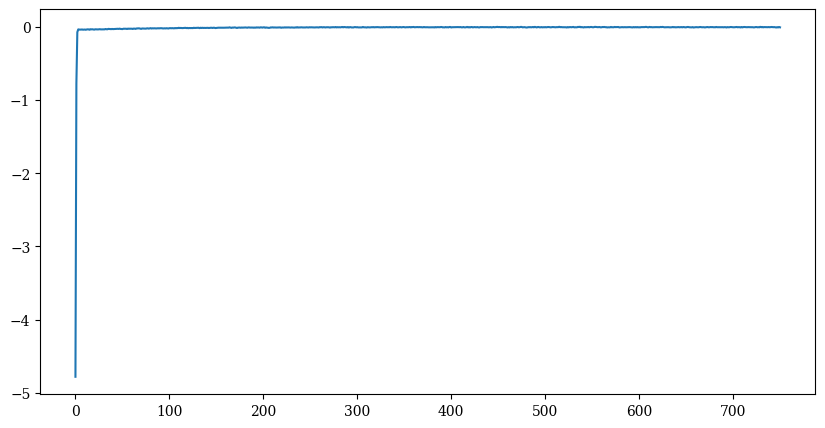

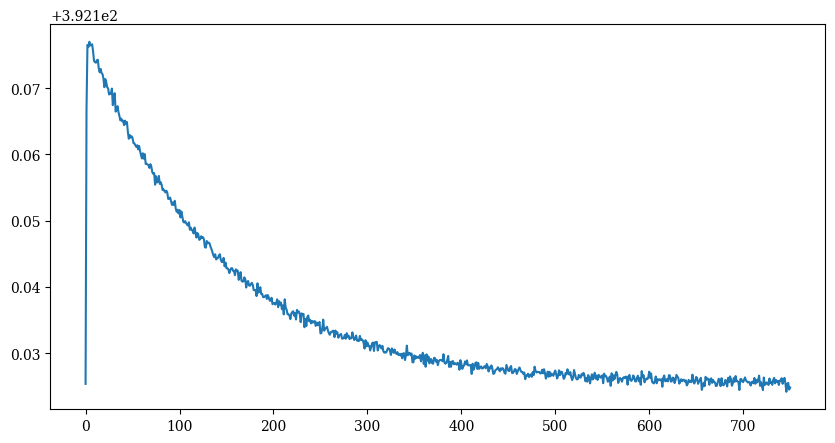

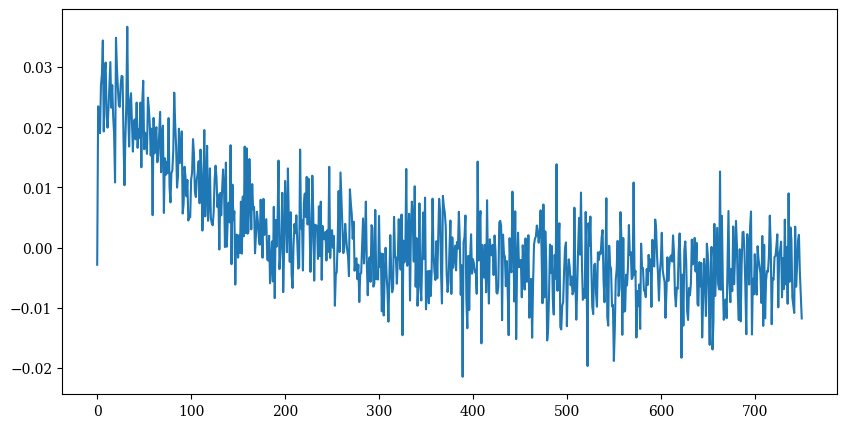

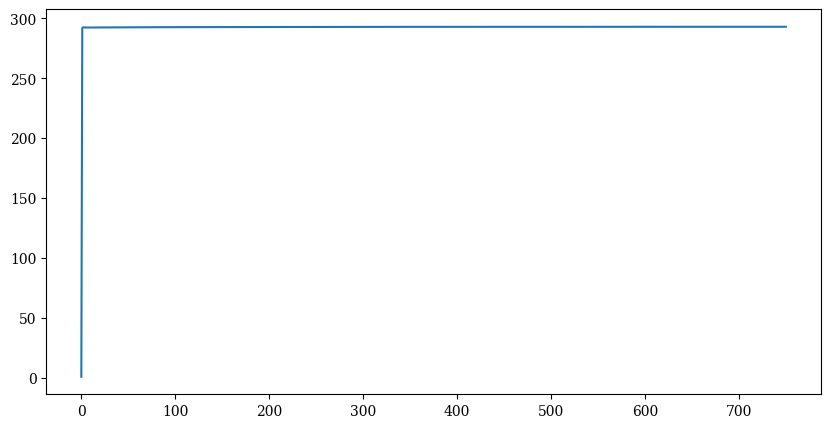

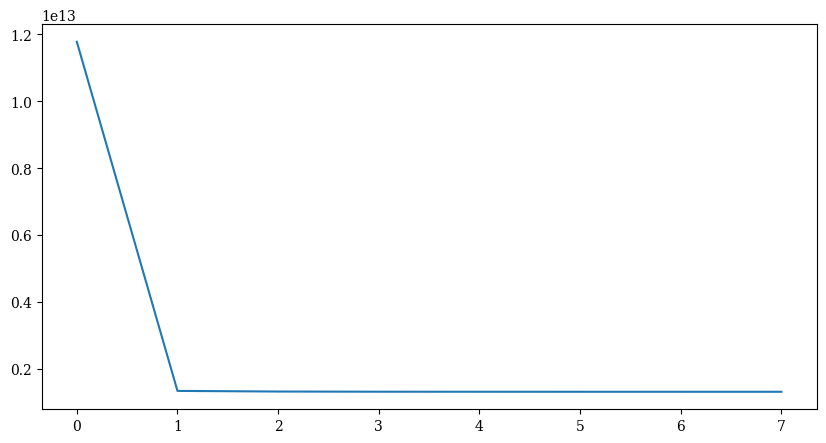

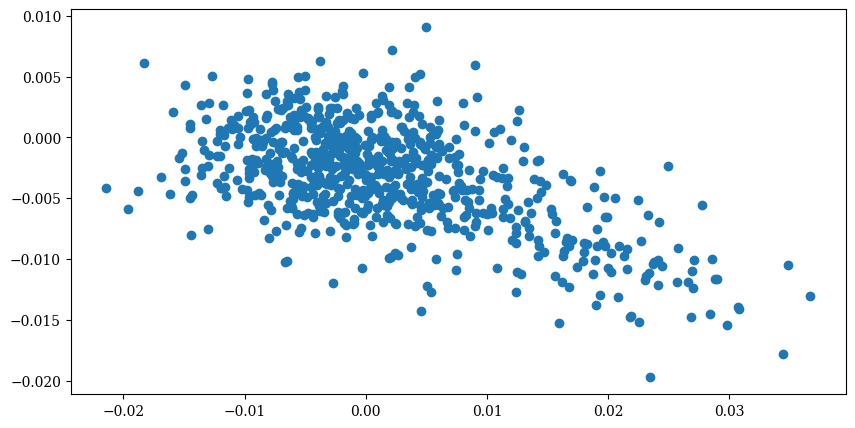

In [ ]:
plt.plot(param_dict['all_p_gain'][:,-1])
plt.show()
plt.plot(param_dict['all_p_cal_src'][:, -1])
plt.show()
plt.plot(param_dict['all_p_cal_src'][:, 0])
plt.show()
plt.plot(param_dict['all_p_ant_nw'][:, 0])
plt.show()

plt.plot(param_dict['all_chi_squared_stats'])
plt.show()

plt.scatter(param_dict['all_p_cal_src'][:, 0], param_dict['all_p_cal_src'][:, 1])
plt.show()

Gibbs Sampling:   0%|          | 1/250 [00:03<12:47,  3.08s/it]

chi_sq:  1314433737367.1753


Gibbs Sampling: 100%|██████████| 250/250 [11:44<00:00,  2.82s/it]


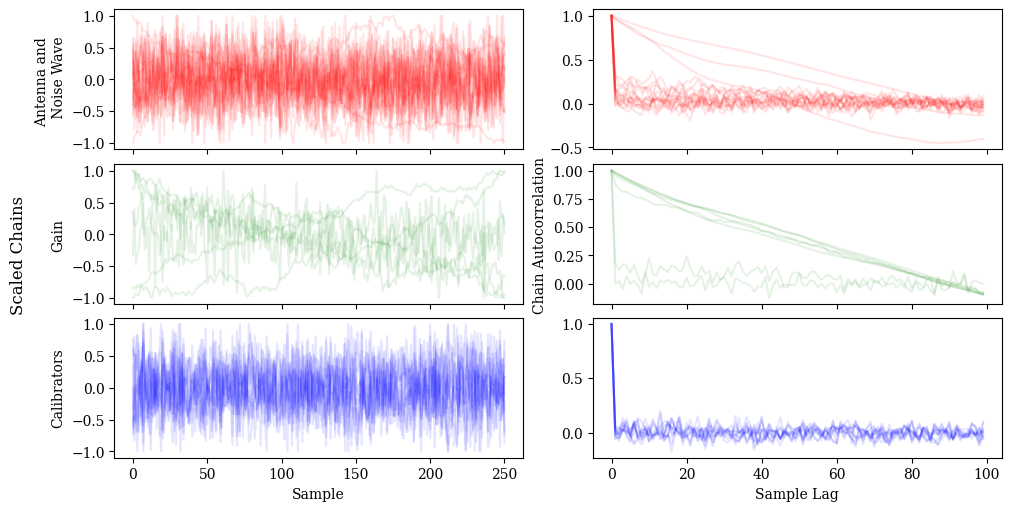

In [ ]:
# extra burn in if need

param_dict = GibbsSampleParams(
    data=observation.data_waterfall.flatten(),
                         N=observation.Nw.flatten(),
                         U_gain=U_gain,
                         X_ant_nw=X_ant_noisewave,
                         X_cal_src=X_calibrator,
                         init_gain_amps=param_dict['all_p_gain'][-1],
                         init_cal_src_amps=param_dict['all_p_cal_src'][-1],
                         init_ant_nw_amps=param_dict['all_p_ant_nw'][-1],
                         cal_src_priors=cal_source_priors,
                         inv_cal_src_prior_cov=cal_source_prior_inv_cov,
                         n_iter=250,
                         Y_cal_src=Y_calibrator,
                         verbose=False,
                         chi_square_interval=500
)


plot_chains_and_auto_correlation(ant_nw_chains=param_dict['all_p_ant_nw'],
            gain_chains=param_dict['all_p_gain'],
            cal_chains=param_dict['all_p_cal_src'],
            alpha=0.1,
            auto_lim=100,
            figsize=(10,5))

In [ ]:
# param_dict = sample_loop(data=observation.data_waterfall.flatten(),
#                          N=observation.Nw.flatten(),
#                          U_gain=U_gain,
#                          X_ant_nw=X_ant_noisewave,
#                          X_cal_src=X_calibrator,
#                          init_gain_amps=param_dict['all_p_gain'][-1],
#                          init_cal_src_amps=param_dict['all_p_cal_src'][-1],
#                          init_ant_nw_amps=param_dict['all_p_ant_nw'][-1],
#                          cal_src_priors=cal_source_priors,
#                          inv_cal_src_prior_cov=cal_source_prior_inv_cov,
#                          n_iter=5000,
#                          fix_cal_source=False,
#                          Y_cal_src=Y_calibrator,
#                          verbose=False,
#                          chi_square_interval=500)

param_dict = GibbsSampleParams(
    data=observation.data_waterfall.flatten(),
                         N=observation.Nw.flatten(),
                         U_gain=U_gain,
                         X_ant_nw=X_ant_noisewave,
                         X_cal_src=X_calibrator,
                         init_gain_amps=param_dict['all_p_gain'][-1],
                         init_cal_src_amps=param_dict['all_p_cal_src'][-1],
                         init_ant_nw_amps=param_dict['all_p_ant_nw'][-1],
                         cal_src_priors=cal_source_priors,
                         inv_cal_src_prior_cov=cal_source_prior_inv_cov,
                         n_iter=5000,
                         Y_cal_src=Y_calibrator,
                         verbose=False,
                         chi_square_interval=500
)

Gibbs Sampling:   0%|          | 1/5000 [00:02<3:48:04,  2.74s/it]

chi_sq:  1314392301016.2788


Gibbs Sampling:  10%|█         | 501/5000 [21:29<2:54:47,  2.33s/it]

chi_sq:  1314373988458.9053


Gibbs Sampling:  20%|██        | 1001/5000 [40:22<2:44:06,  2.46s/it]

chi_sq:  1314376016507.1167


... (11 outputs left out)

chi_sq:  1314374669722.0332


Gibbs Sampling:  90%|█████████ | 4501/5000 [2:46:20<20:29,  2.46s/it]

chi_sq:  1314370667183.3062


Gibbs Sampling: 100%|██████████| 5000/5000 [3:03:03<00:00,  2.20s/it]


In [23]:
savedir = '../chains/case3'


In [22]:

# np.savez_compressed(f'{savedir}/gibbs_sample_case3.npz', **param_dict)


In [25]:

param_dict = np.load(f'{savedir}/gibbs_sample_case3_test.npz', allow_pickle=True)

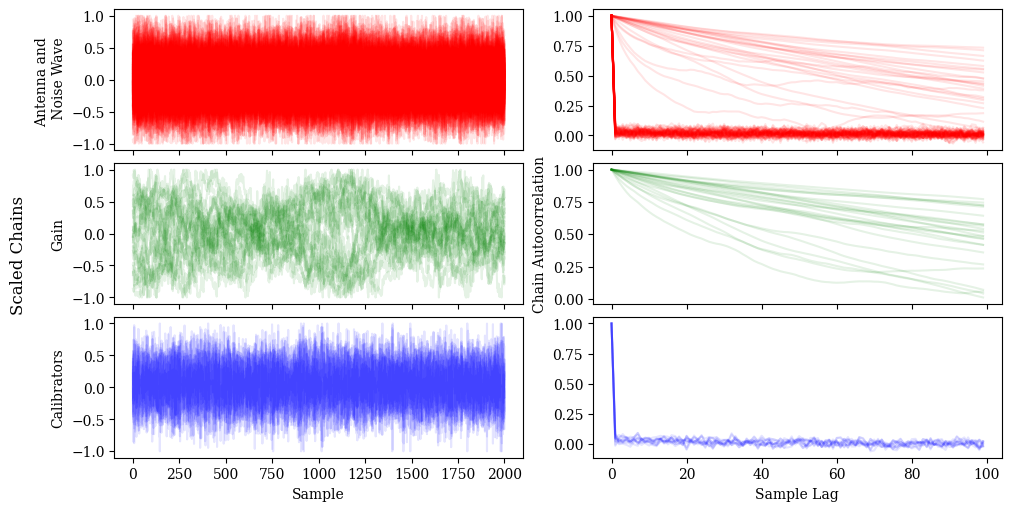

In [26]:
plot_chains_and_auto_correlation(ant_nw_chains=param_dict['all_p_ant_nw'],
            gain_chains=param_dict['all_p_gain'],
            cal_chains=param_dict['all_p_cal_src'],
            alpha=0.1,
            auto_lim=100,
            figsize=(10,5))

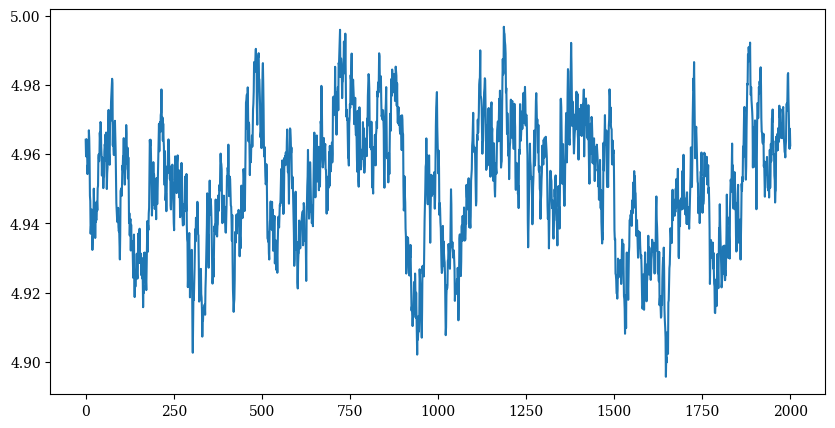

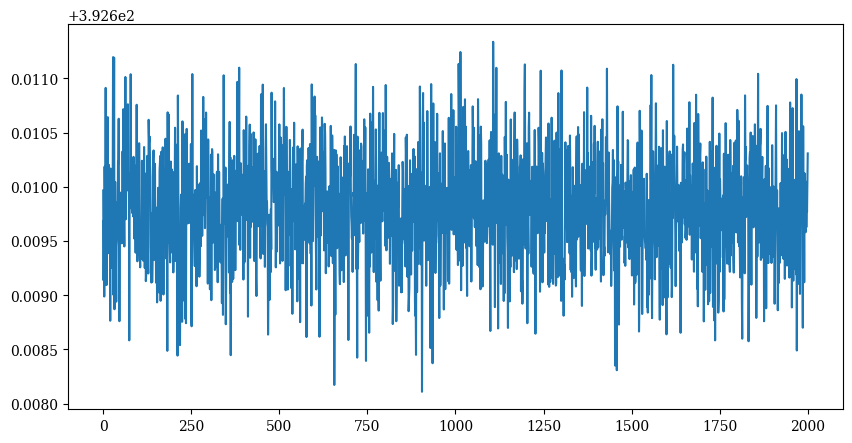

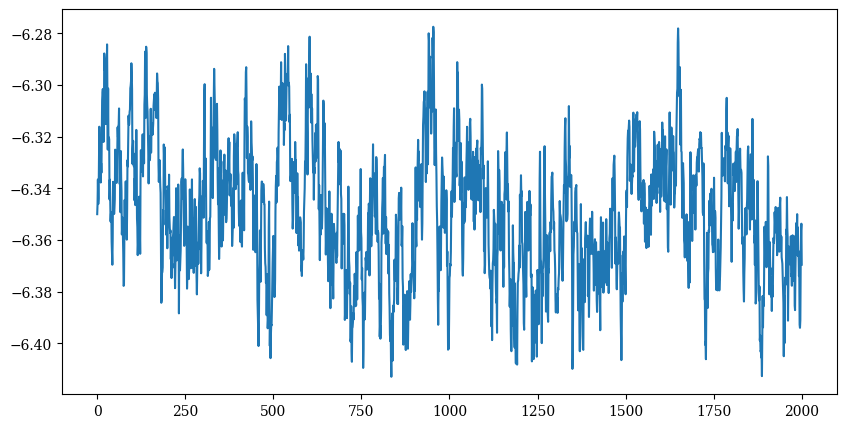

392.6097990549759


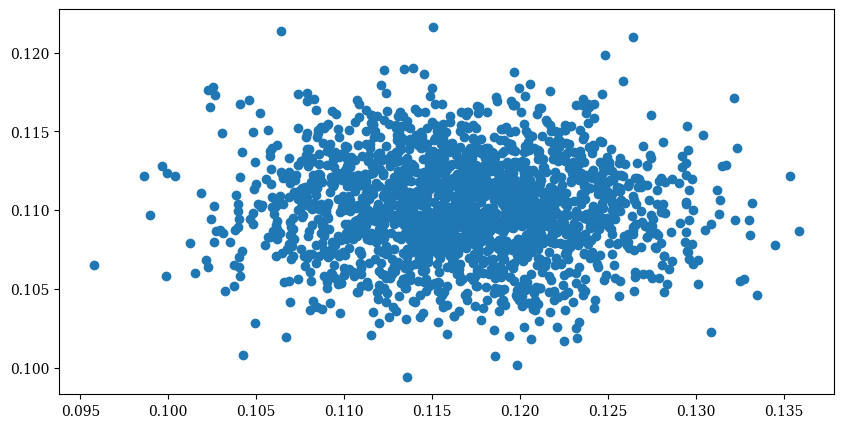

In [27]:
plt.plot(param_dict['all_p_gain'][:,-1])
plt.show()
plt.plot(param_dict['all_p_cal_src'][:, -1])
plt.show()
plt.plot(param_dict['all_p_ant_nw'][:, -1])
plt.show()

print(np.mean(param_dict['all_p_cal_src'][:, -1]))

plt.scatter(param_dict['all_p_cal_src'][:, 0], param_dict['all_p_cal_src'][:, 1])
plt.show()



[ 2.97395387e+02  6.95578941e-01  2.03678034e+00  8.49649312e-01
  3.45150192e-01 -4.13945678e+00  1.78934062e+00  1.03874511e+00
  3.15441763e-01 -2.40918606e-02  3.79272560e+00 -3.11840499e+00
 -6.24838175e+00 -1.73542534e+00  7.07021636e-01 -4.69086222e-01
  1.07270091e+00 -1.33121474e+00  1.63011705e+00 -6.43033570e-01
  5.36477509e-01 -1.30642975e+00  1.68116311e+00 -1.77463158e+00
  7.83610916e-01 -2.54156014e+01  5.32281201e-02 -2.56435863e+00
  4.55789304e-02 -2.29335030e+00  2.49253214e+00  6.34785601e-01
 -4.00404875e+00 -9.85726785e-02  6.12460979e-02  2.30057241e+00
 -9.68260386e-01  8.78621587e+00 -1.50114104e+00  2.83915748e+00
  2.57929949e-01 -3.23766180e-01 -1.75631544e-01  7.24773504e-01
 -1.07191975e+00 -2.69574623e-01  5.25597982e-01  4.40586677e-02
 -7.88000962e-01  1.54281031e+00  2.50353308e+01  1.98058947e+00
 -2.18760923e-01 -2.30746608e+00 -5.37174377e+00  5.89241816e+00
  4.25114882e+00 -2.40389304e-01 -2.55655729e-01  1.65003423e-02
 -4.14529275e+00  4.08805

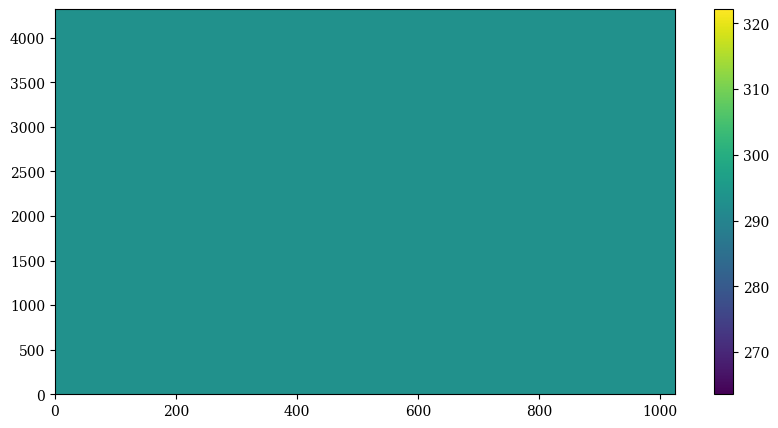

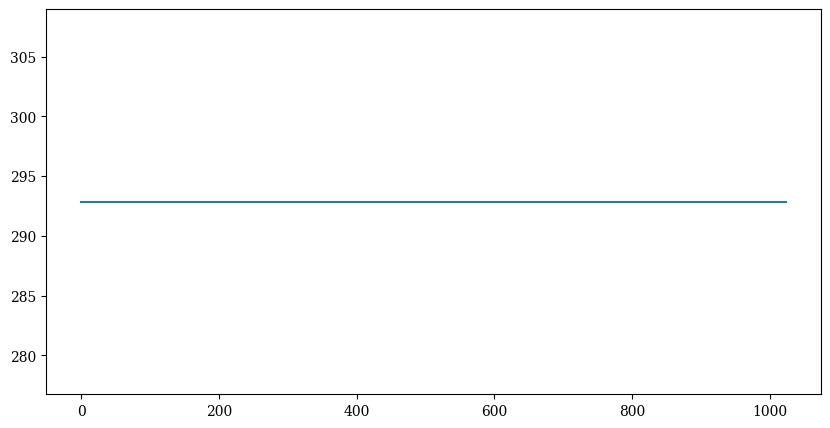

In [28]:
# Recovered Antenna

median_p_ant_nw = np.mean(param_dict['all_p_ant_nw'], axis=0)
median_p_ant = median_p_ant_nw[:len(X_antenna[0])]
median_p_nw = median_p_ant_nw[len(X_antenna[0]):]
print(median_p_nw)


reconstructed_antenna = antenna_basis.basis_matrix @ median_p_ant
reconstructed_antenna = np.reshape(reconstructed_antenna, shape=observation.data_waterfall.shape)

plt.pcolormesh(reconstructed_antenna)
plt.colorbar()
plt.show()

plt.plot(reconstructed_antenna.mean(axis=0))
plt.show()

[ 458.43551881 -237.79202919 -136.07774021   23.90569017  -11.22415143
  -80.86466297   79.27048873    7.58654834  -11.73961365    0.77107404
  -51.81193837   95.47194008    1.80946444  -40.1448748     7.68045646
   87.60606666  -22.81088567  -47.29763904   16.24723924   -8.89168567
    3.64500253   -8.96361373   12.10530416  -12.17510613    4.95237745]


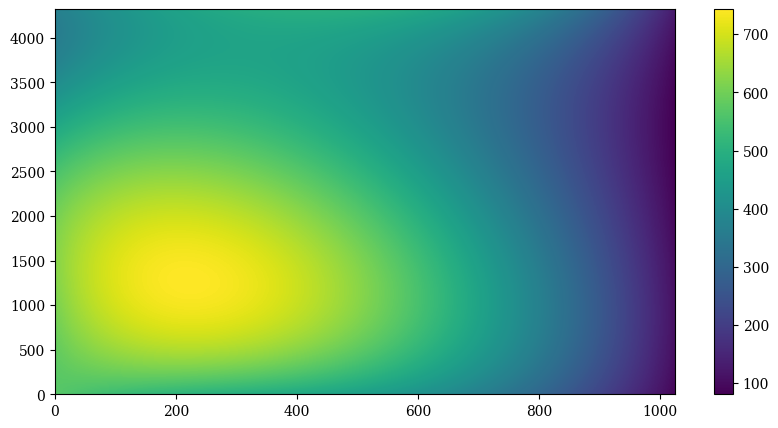

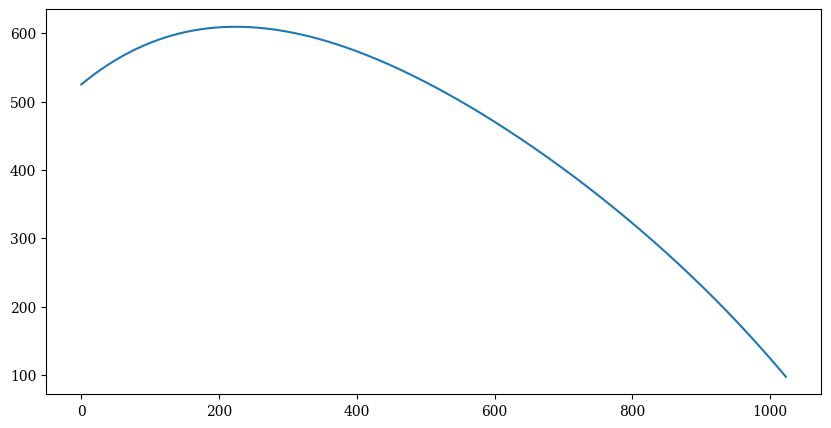

In [29]:
median_gains = np.median(param_dict['all_p_gain'], axis=0)

print(median_gains)

reconstructed_gains = gains_basis.basis_matrix @ median_gains

reconstructed_gains = np.reshape(reconstructed_gains, shape=observation.data_waterfall.shape)

plt.pcolormesh(reconstructed_gains)
plt.colorbar()
plt.show()

plt.plot(np.mean(reconstructed_gains, axis=0))
plt.show()

In [30]:
import h5py
sim_filepath = '../simulated_data/case_3/sim_data.hdf5_sim'
with h5py.File(sim_filepath) as f:
    t_unc_sim = f['t_unc'][()]
    t_sin_sim = f['t_sin'][()]
    t_cos_sim = f['t_cos'][()]
    t_rx_sim = f['t_0'][()]
    gain_sim = f['gains'][()]
    t_amb_sim = f['t_src_open'][()]
    t_heated_sim = f['t_src_heated_load'][()]

## Calibrator Recovery

In [31]:
def plot_calibrator_temperatures(observation_obj:ObservationReader,
                                 ambient_chains,
                                 ambient_basis,
                                 heated_chains,
                                 heated_basis,
                                 true_ambient,
                                 true_heated,
                                 figsize=(6,10),
                                 resid_lims=0.01,
                                 alpha_lines=0.4,
                                 ):

    def plot_bounds(basis,
                    amps,
                    fig,
                    full_ax,
                    resid_ax,
                    color,
                    c_true,
                    c_measured,
                    alpha,
                    measured_tod,
                    true_temperatures,
                    ):
        
        def reproduce_tod(amps):
            rec = basis @ amps
            return rec

        recovered_tod = np.array([reproduce_tod(a) for a in amps])
        med_rec = np.quantile(recovered_tod,
                                          0.5, axis=0)
        sigma_bounds = [
             np.quantile(recovered_tod, 0.5-(0.68/2), axis=0),
             np.quantile(recovered_tod, 0.5+(0.68/2), axis=0)
                    ]
        three_sigma_bounds = [
            np.quantile(recovered_tod, 0.5-(0.997/2), axis=0),
            np.quantile(recovered_tod, 0.5+(0.997/2), axis=0),
            ]
        
        full_ax.plot(observation_obj.times, true_temperatures, c=c_true, label='True')
        full_ax.plot(observation_obj.times, med_rec, c=color, label='Max Prob.')
        
        full_ax.fill_between(observation_obj.times, sigma_bounds[0], sigma_bounds[-1],
                                     color=color, alpha=2*alpha, label=r'$1\,\sigma$')
        
        full_ax.fill_between(observation_obj.times, three_sigma_bounds[0], three_sigma_bounds[-1],
                             color=color, alpha=alpha, label=r'$3\,\sigma$')

        
        resid_ax.plot(observation_obj.times, med_rec - true_temperatures, c=color)
        resid_ax.fill_between(observation_obj.times, sigma_bounds[0]-true_temperatures,
                              sigma_bounds[-1]-true_temperatures,
                              color=color, alpha=2*alpha)
        resid_ax.fill_between(observation_obj.times, three_sigma_bounds[0]-true_temperatures,
                              three_sigma_bounds[-1]-true_temperatures,
                                                     color=color, alpha=alpha)
        
        resid_ax.plot(observation_obj.times, np.zeros_like(observation_obj.times), ls='--', c='black')
        # resid_ax.scatter(observation_obj.times, np.zeros_like(observation_obj.times), c='black')

        # resid_ax.plot(observation.times, measured_tod - true_temperatures, ls='dotted', c='grey',
        #               alpha=0.25)

        resid_ax.scatter(observation.times, measured_tod - true_temperatures, c='grey',
                              alpha=0.1)

        # full_ax.plot(observation_obj.temperature_times, measured_tod, c=c_measured,
        #              label='Measured', ls='dotted')
        
        full_ax.scatter(observation.times, measured_tod, c='grey',
                                      alpha=0.1)

    fig, axes = plt.subplots(nrows=3, ncols=1, layout='constrained', sharex=True,
                             figsize=figsize)

    plot_bounds(basis=ambient_basis,
                amps=ambient_chains,
                fig=fig,
                full_ax=axes[0],
                resid_ax=axes[2],
                color='blue',
                c_true='black',
                c_measured='black',
                alpha=alpha_lines,
                measured_tod=observation_obj.temperatures['ambient'],
                true_temperatures=true_ambient,
                )

    plot_bounds(basis=heated_basis,
                    amps=heated_chains,
                    fig=fig,
                    full_ax=axes[1],
                    resid_ax=axes[2],
                    color='red',
                    c_true='black',
                    c_measured='black',
                    alpha=alpha_lines,
                    measured_tod=observation_obj.temperatures['heated'],
                    true_temperatures=true_heated,
                    )

    axes[-1].set_ylim(-resid_lims, resid_lims)
    fig.supxlabel('Times [s]')
    axes[0].set_ylabel('Temperatures [K]')
    axes[-1].set_ylabel('Residuals [K]')

    plt.show()

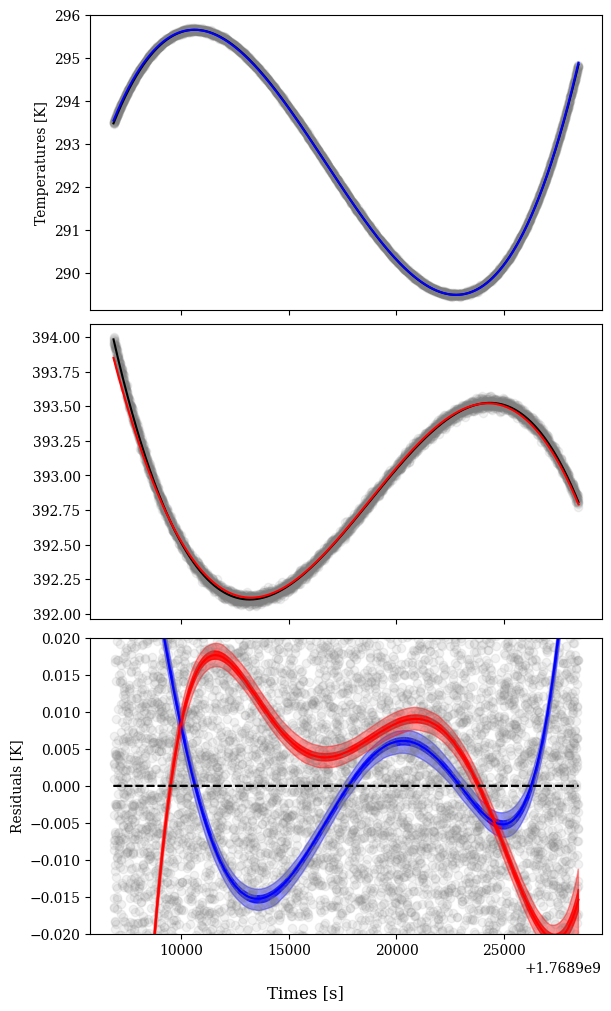

In [32]:
t_amb_chains = param_dict['all_p_cal_src'][:,calibrator_slice_dict_y['ambient']]
t_heated_chains = param_dict['all_p_cal_src'][:,calibrator_slice_dict_y['heated']]

plot_calibrator_temperatures(observation_obj=observation,
                                 ambient_chains=t_amb_chains,
                                 ambient_basis=ambient_basis_y.basis_matrix,
                                 heated_chains=t_heated_chains,
                                 heated_basis=heated_basis_y.basis_matrix,
                                 true_ambient=t_amb_sim,
                                 true_heated=t_heated_sim,
                                 resid_lims=0.02
                                 )



## Gain Recovery

[ 458.43551881 -237.79202919 -136.07774021   23.90569017  -11.22415143
  -80.86466297   79.27048873    7.58654834  -11.73961365    0.77107404
  -51.81193837   95.47194008    1.80946444  -40.1448748     7.68045646
   87.60606666  -22.81088567  -47.29763904   16.24723924   -8.89168567
    3.64500253   -8.96361373   12.10530416  -12.17510613    4.95237745]


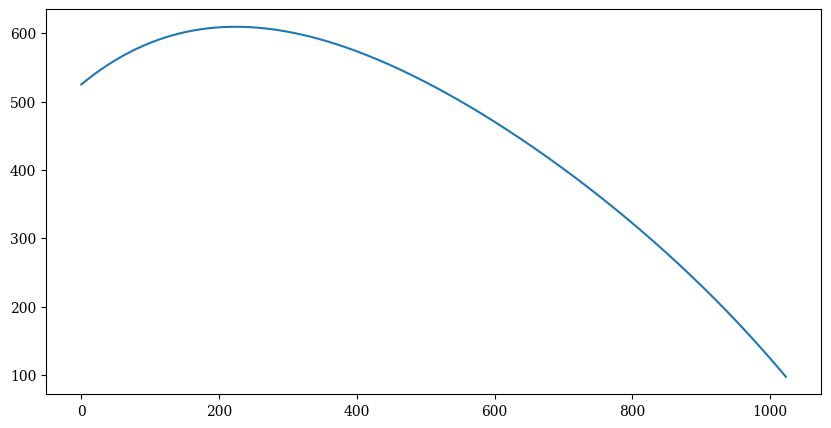

In [33]:
median_gains = np.median(param_dict['all_p_gain'], axis=0)
mean_gains = np.mean(param_dict['all_p_gain'], axis=0)
print(median_gains)

reconstructed_gains = gains_basis.basis_matrix @ median_gains

reconstructed_gains = np.reshape(reconstructed_gains, shape=observation.data_waterfall.shape)

plt.plot(np.mean(reconstructed_gains, axis=0))
plt.show()

In [34]:
def compare_sim_and_recontructed(simulated_surface,
                                 basis_obj:BasisConstructor,
                                 amplitudes,
                                 times,
                                 freqs,
                                 cmap_rec='viridis',
                                 cmap_res='RdBu',
                                 perc_diff=False,
                                 surface_label='',
                                 residvminvmax=None,
                                 figsize=(10,8)):
    fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, sharex=True, layout='constrained',
                                        figsize=figsize)

    recovered_surface = basis_obj.basis_matrix @ amplitudes
    recovered_surface = np.reshape(recovered_surface, shape=simulated_surface.shape)

    vmin = np.min(np.array([simulated_surface, recovered_surface]))
    vmax = np.max(np.array([simulated_surface, recovered_surface]))
    
    im1 = ax1.pcolormesh(freqs, times, simulated_surface, cmap=cmap_rec, vmin=vmin, vmax=vmax)
    ax1.set_title('True Simulated')

    im2 = ax2.pcolormesh(freqs, times, recovered_surface, cmap=cmap_rec, vmin=vmin, vmax=vmax)
    ax2.set_title('Recovered')

    if perc_diff:
        res = 200 * (recovered_surface - simulated_surface) / (recovered_surface+simulated_surface)
    else:
        res = recovered_surface - simulated_surface
    

    if residvminvmax is not None:
        im3 = ax3.pcolormesh(freqs, times, res, cmap=cmap_res,
                                 vmin=-residvminvmax,
                                 vmax=residvminvmax)
    else:
        im3 = ax3.pcolormesh(freqs, times, res, cmap=cmap_res)

    fig.colorbar(im1, ax=[ax1, ax2], label=surface_label)

    if perc_diff:
        res_label='% Difference'
    else:
        res_label='Residual [K]'
    fig.colorbar(im3, ax=ax3, label=res_label)

    fig.supxlabel('Freqs [Hz]')
    fig.supylabel('Time [s]')
    plt.show()
    

## Noise Wave Param Recovery

In [35]:
param_dict['all_p_ant_nw'][ant_noise_wave_slice_dict['noise_wave']]

mean_ant_nw = param_dict['all_p_ant_nw'].mean(axis=0)

median_ant_nw = np.mean(param_dict['all_p_ant_nw'], axis=0)

# print(ant_noise_wave_slice_dict['noise_wave'])

mean_nw = median_ant_nw[ant_noise_wave_slice_dict['noise_wave']]
print(nw_slice_dict)

mean_unc = mean_nw[nw_slice_dict['unc']]
mean_cos = mean_nw[nw_slice_dict['cos']]
mean_sin = mean_nw[nw_slice_dict['sin']]
mean_rx = mean_nw[nw_slice_dict['rx']]

print(mean_unc, mean_cos, mean_sin, mean_rx)

{'unc': slice(0, 25, None), 'cos': slice(25, 50, None), 'sin': slice(50, 75, None), 'rx': slice(75, 100, None)}
[ 2.97395387e+02  6.95578941e-01  2.03678034e+00  8.49649312e-01
  3.45150192e-01 -4.13945678e+00  1.78934062e+00  1.03874511e+00
  3.15441763e-01 -2.40918606e-02  3.79272560e+00 -3.11840499e+00
 -6.24838175e+00 -1.73542534e+00  7.07021636e-01 -4.69086222e-01
  1.07270091e+00 -1.33121474e+00  1.63011705e+00 -6.43033570e-01
  5.36477509e-01 -1.30642975e+00  1.68116311e+00 -1.77463158e+00
  7.83610916e-01] [-25.41560142   0.05322812  -2.56435863   0.04557893  -2.2933503
   2.49253214   0.6347856   -4.00404875  -0.09857268   0.0612461
   2.30057241  -0.96826039   8.78621587  -1.50114104   2.83915748
   0.25792995  -0.32376618  -0.17563154   0.7247735   -1.07191975
  -0.26957462   0.52559798   0.04405867  -0.78800096   1.54281031] [ 2.50353308e+01  1.98058947e+00 -2.18760923e-01 -2.30746608e+00
 -5.37174377e+00  5.89241816e+00  4.25114882e+00 -2.40389304e-01
 -2.55655729e-01  1.6

In [36]:
figsize=(5,10)

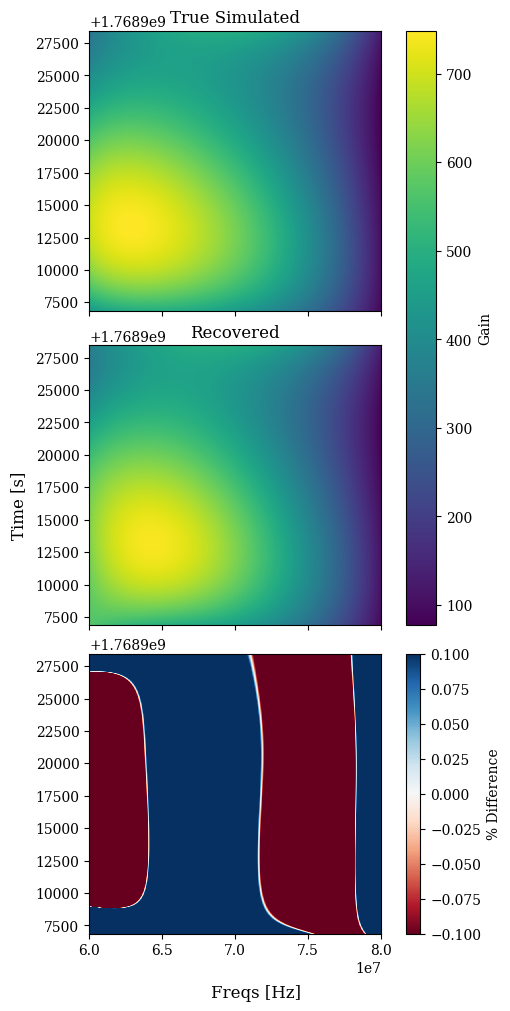

In [37]:
compare_sim_and_recontructed(gain_sim,
                             gains_basis,
                             mean_gains,
                             observation.times,
                             observation.freqs,
                             surface_label='Gain',
                             perc_diff=True,
                             residvminvmax=0.1,
                             figsize=figsize)

In [38]:
# figsize=(5,10)

# compare_sim_and_recontructed(t_unc_sim,
#                              unc_basis,
#                              mean_unc,
#                              observation.times,
#                              observation.freqs,
#                              perc_diff=True,
#                              residvminvmax=0.5,
#                              surface_label=r'$T_{\rm unc}$ [K]',
#                              figsize=figsize)
# compare_sim_and_recontructed(t_cos_sim,
#                              cos_basis,
#                              mean_cos,
#                              observation.times,
#                              observation.freqs,
#                              perc_diff=True,
#                              residvminvmax=0.5,
#                              surface_label=r'$T_{\rm cos}$ [K]',
#                              figsize=figsize)
# compare_sim_and_recontructed(t_sin_sim,
#                              sin_basis,
#                              mean_sin,
#                              observation.times,
#                              observation.freqs,
#                              perc_diff=True,
#                              residvminvmax=0.5,
#                              surface_label=r'$T_{\rm sin}$ [K]',
#                              figsize=figsize)
# compare_sim_and_recontructed(t_rx_sim,
#                              rx_basis,
#                              mean_rx,
#                              observation.times,
#                              observation.freqs,
#                              perc_diff=True,
#                              residvminvmax=0.5,
#                              surface_label=r'$T_{\rm rx}$ [K]',
#                              figsize=figsize)

In [39]:
def plot_corner(
    chains: np.ndarray,
    labels: list[str] | None = None,
    truths: list[float] | None = None,
    title: str | None = None,
    **corner_kwargs,
):
    """
    Plot posterior densities and parameter correlations using corner.py.

    Parameters
    ----------
    chains : np.ndarray
        Array of parameter chains with shape:
        (n_samples, n_parameters)

    labels : list[str], optional
        Names of the parameters.

    truths : list[float], optional
        True/reference values for each parameter.

    title : str, optional
        Optional figure title.

    **corner_kwargs
        Additional keyword arguments passed to corner.corner().

    Returns
    -------
    fig : matplotlib.figure.Figure
        The generated corner plot figure.
    """

    import corner
    chains = np.asarray(chains)

    if chains.ndim != 2:
        raise ValueError(
            f"chains must be 2D with shape (n_samples, n_parameters), "
            f"got shape {chains.shape}"
        )

    n_parameters = chains.shape[1]

    if labels is not None and len(labels) != n_parameters:
        raise ValueError(
            f"Expected {n_parameters} labels, got {len(labels)}"
        )

    if truths is not None and len(truths) != n_parameters:
        raise ValueError(
            f"Expected {n_parameters} truths, got {len(truths)}"
        )

    one_sigma_1d = 0.683
    q_lower = 1 / 2 - one_sigma_1d / 2
    q_upper = 1 / 2 + one_sigma_1d / 2

    one_sigma_2d = 0.393

    three_sigma_1d = 0.997
    q_lower_3 = 1 / 2 - three_sigma_1d / 2
    q_upper_3 = 1 / 2 + three_sigma_1d / 2

    fig = corner.corner(
        chains,
        labels=labels,
        truths=truths,
        quantiles=(q_lower, q_upper),
        #levels=one_sigma_2d
        **corner_kwargs,
    )

    if title is not None:
        fig.suptitle(title)

    return fig


In [40]:
noise_wave_chains = param_dict['all_p_ant_nw'][:,ant_noise_wave_slice_dict['noise_wave']]


noise_diode_chain = param_dict['all_p_ant_nw'][:,ant_noise_wave_slice_dict['antenna']]

print(noise_diode_chain[:,-1])


[292.85951808 292.85853536 292.85722788 ... 292.85590999 292.86026247
 292.86224526]


[[ 1.23693589e-01  1.10681838e-01  8.54031527e+00  2.25735168e+00
  -7.99023486e+00  2.91844700e+02]
 [ 1.09015792e-01  1.05450436e-01  8.55739707e+00  2.26339212e+00
  -7.99402732e+00  2.91843845e+02]
 [ 1.07872460e-01  1.16922432e-01  8.55718279e+00  2.25413063e+00
  -7.99393920e+00  2.91844566e+02]
 ...
 [ 1.11371411e-01  1.11386094e-01  8.55665692e+00  2.25818951e+00
  -7.99541431e+00  2.91843600e+02]
 [ 1.15439732e-01  1.08691547e-01  8.55319776e+00  2.25911165e+00
  -7.99468336e+00  2.91844179e+02]
 [ 1.02943356e-01  1.08721678e-01  8.56416666e+00  2.25914154e+00
  -7.99497590e+00  2.91844655e+02]] [[ 1.96287552e-01 -1.41249299e-01 -2.71563661e+00  8.49173095e-01
   1.99087522e+00  3.92609966e+02]
 [ 1.98786234e-01 -1.39707341e-01 -2.71706316e+00  8.51220658e-01
   1.99035994e+00  3.92609138e+02]
 [ 2.09936921e-01 -1.42287158e-01 -2.72998537e+00  8.50971314e-01
   1.99329659e+00  3.92609692e+02]
 ...
 [ 1.99703034e-01 -1.39687299e-01 -2.71747173e+00  8.49705844e-01
   1.99007702e

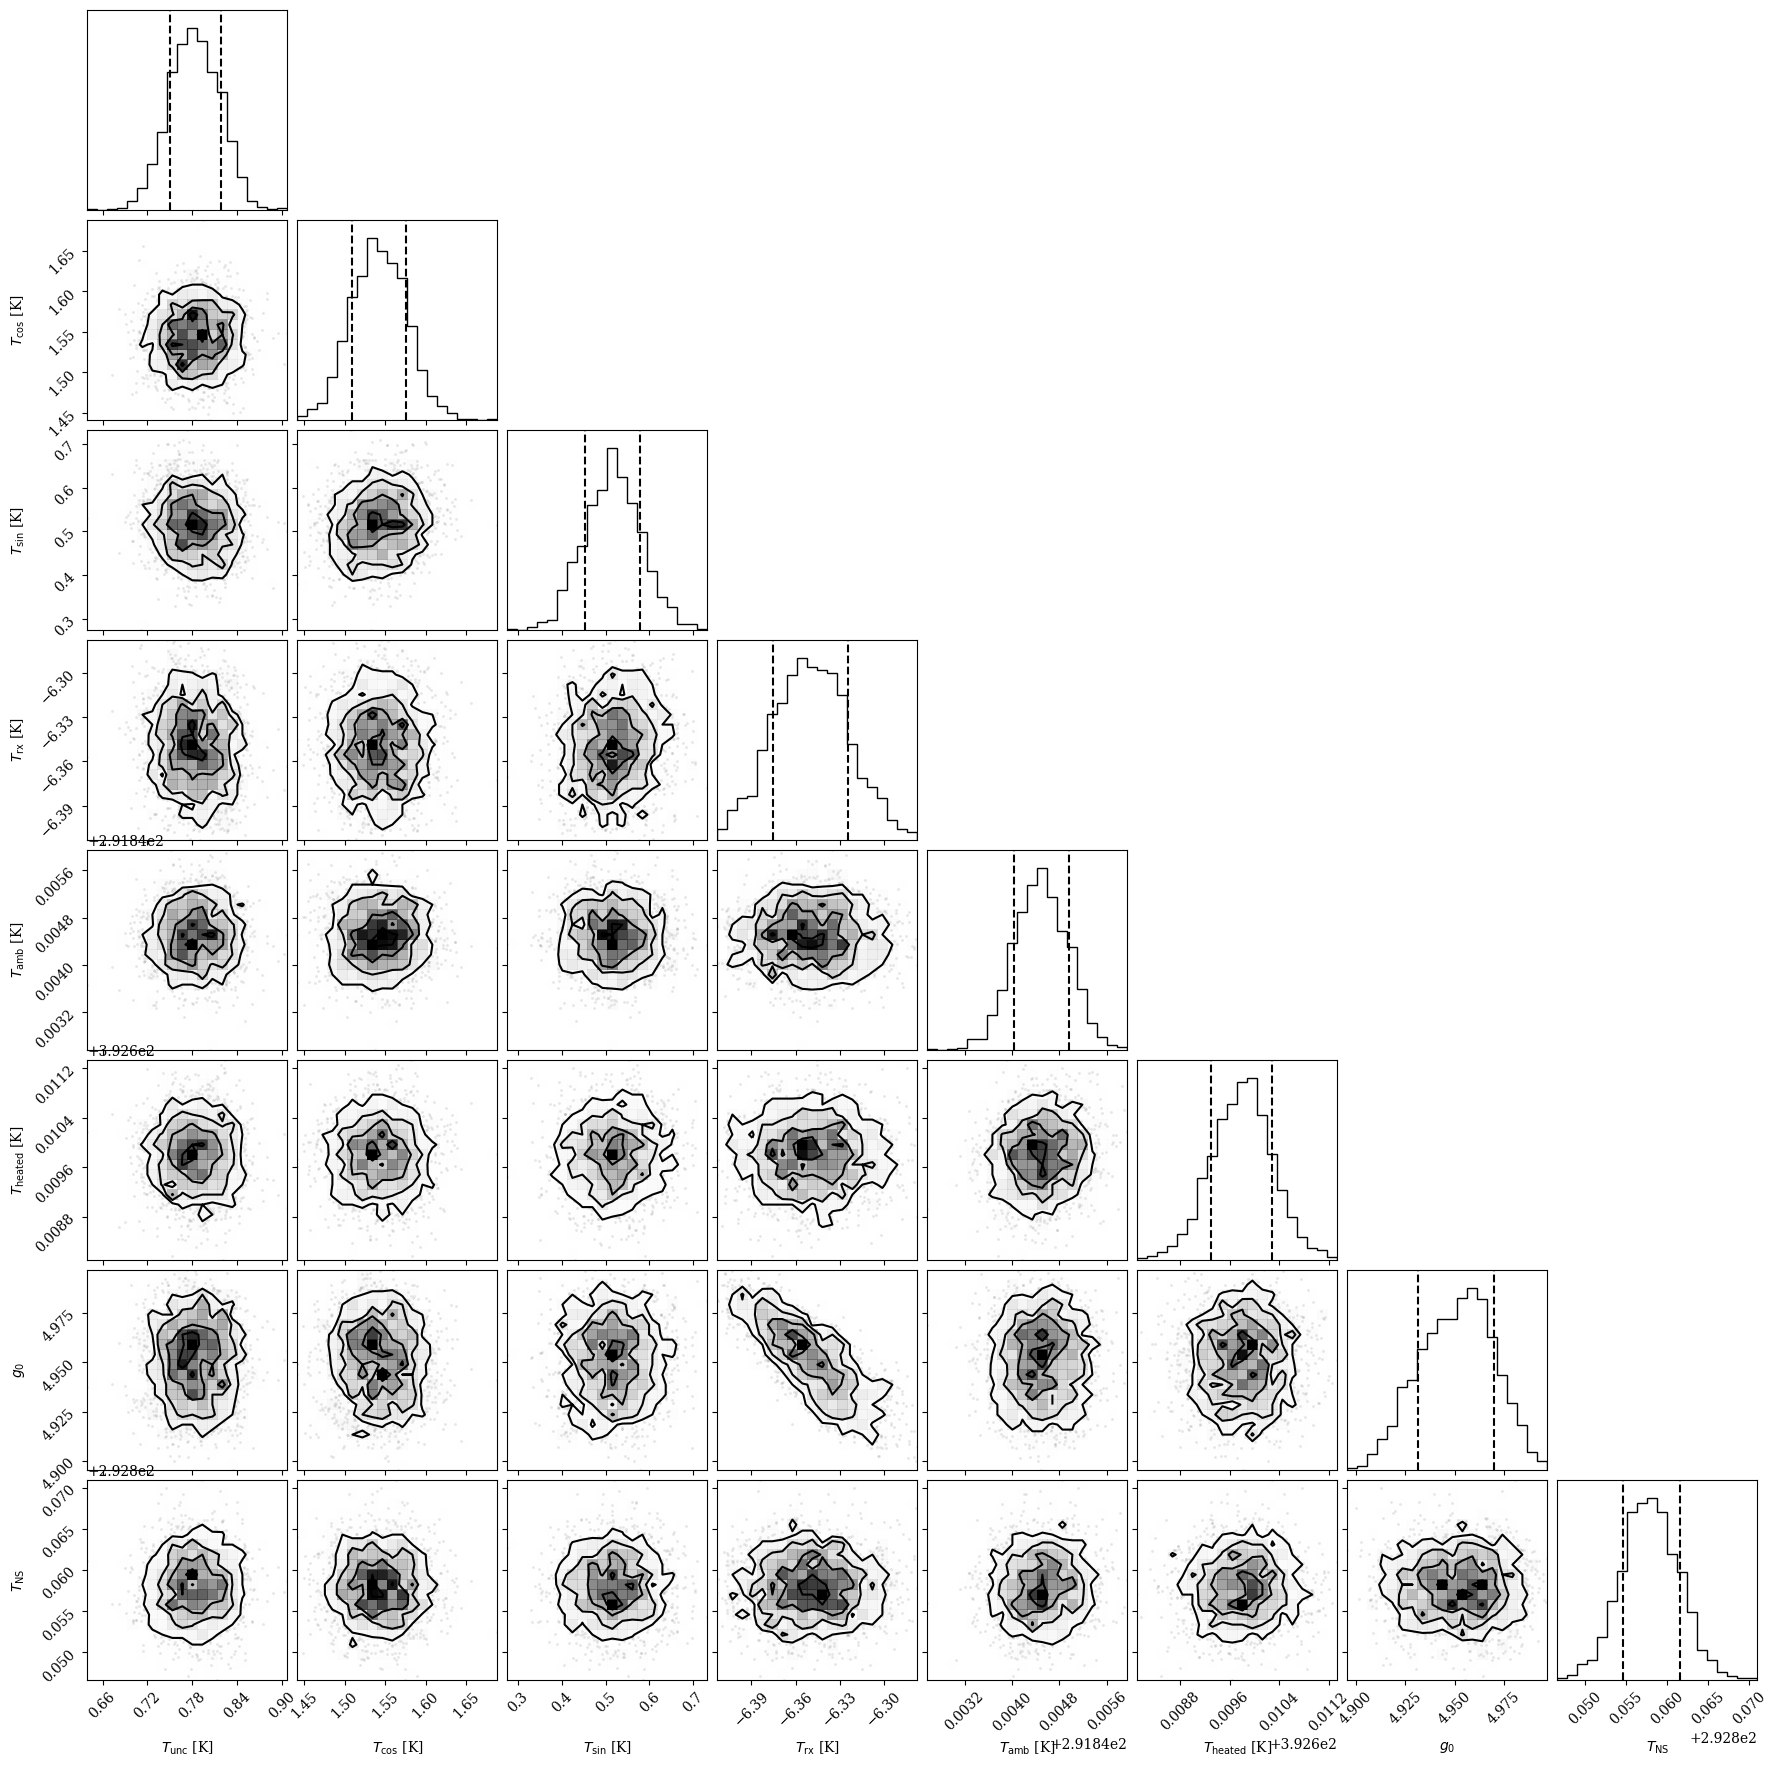

In [41]:

t_unc_chains = noise_wave_chains[:,nw_slice_dict['unc']]
t_sin_chains = noise_wave_chains[:,nw_slice_dict['sin']]
t_cos_chains = noise_wave_chains[:,nw_slice_dict['cos']]
t_rx_chains = noise_wave_chains[:,nw_slice_dict['rx']]

t_amb_chains = param_dict['all_p_cal_src'][:,calibrator_slice_dict_y['ambient']]
t_heated_chains = param_dict['all_p_cal_src'][:,calibrator_slice_dict_y['heated']]
print(t_amb_chains, t_heated_chains)

param_dict['all_p_gain']

gain_chain = param_dict['all_p_gain'][:,-1]



chains = np.column_stack([
    t_unc_chains[:,-1],
    t_cos_chains[:,-1],
    t_sin_chains[:,-1],
    t_rx_chains[:,-1],
    t_amb_chains[:,-1],
    t_heated_chains[:,-1],
    gain_chain,
    noise_diode_chain[:,-1]
])

fig = plot_corner(
    chains,
    labels=[
        r'$T_{\rm unc}$ [K]',
        r'$T_{\rm cos}$ [K]',
        r'$T_{\rm sin}$ [K]',
        r'$T_{\rm rx}$ [K]',
        r'$T_{\rm amb}$ [K]',
        r'$T_{\rm heated}$ [K]',
        r'$g_0$',
        r'$T_{\rm NS}$'
    ],
    truths=[
        np.mean(t_unc_sim),
        np.mean(t_cos_sim),
        np.mean(t_sin_sim),
        np.mean(t_rx_sim),
        293,
        293+150,
        np.mean(gain_sim),
        2600
    ]
)

plt.show()

# Construct $z$-score waterfall

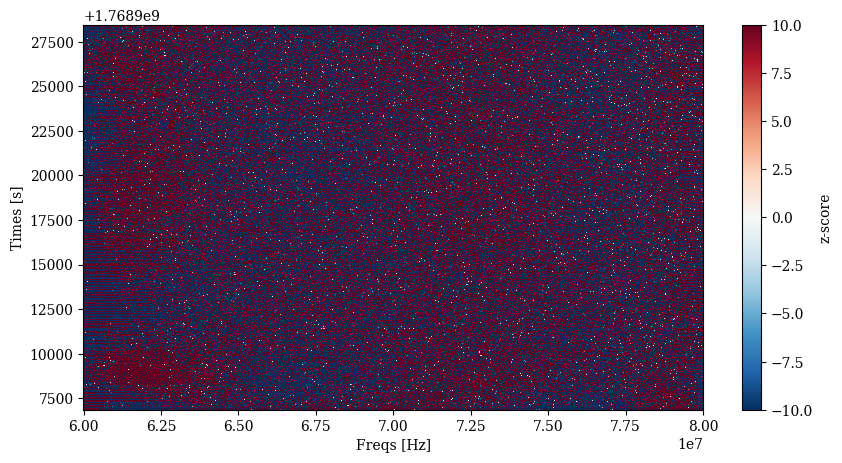

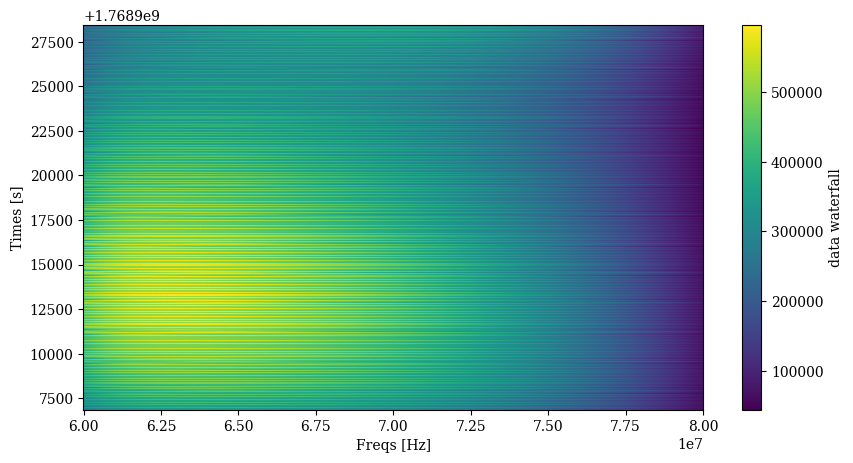

404.08436192478104


In [42]:
mad_model = (gains_basis.basis_matrix @ param_dict['all_p_gain'].mean(axis=0)) *\
    ((X_ant_noisewave @ param_dict['all_p_ant_nw'].mean(axis=0) + X_calibrator @ param_dict['all_p_cal_src'].mean(axis=0)))

cov = observation.Nw.flatten() * mad_model
sigma = np.sqrt(cov)
del cov

z = (observation.data_waterfall.flatten() - mad_model) / sigma
z = np.reshape(z, observation.data_waterfall.shape)

plt.pcolormesh(observation.freqs,
               observation.times,
               z,
               vmin=-10,
               vmax=10,
               cmap='RdBu_r')
plt.colorbar(label='z-score')
plt.ylabel('Times [s]')
plt.xlabel('Freqs [Hz]')
plt.show()


plt.pcolormesh(observation.freqs,
               observation.times,
               observation.data_waterfall,)
plt.colorbar(label='data waterfall')
plt.ylabel('Times [s]')
plt.xlabel('Freqs [Hz]')
plt.show()

print(np.median(np.abs(z)))

### Plot all Receiver calibration terms


In [43]:
def compare_sim_and_recontructed_all(true_gain_surface,
                                     gain_amplitudes,
                                     gain_basis:BasisConstructor,
                                     true_t_unc_surface,
                                     t_unc_amplitudes,
                                     t_unc_basis,
                                     true_t_cos_surface,
                                     t_cos_amplitudes,
                                     t_cos_basis:BasisConstructor,
                                     true_t_sin_surface,
                                     t_sin_amplitudes,
                                     t_sin_basis:BasisConstructor,
                                     true_t_rx_surface,
                                     t_rx_amplitudes,
                                     t_rx_basis:BasisConstructor,
                                     waterfall_shape,
                                     times,
                                     freqs,
                                     cmap_rec='viridis',
                                     cmap_res='RdBu',
                                     perc_diff=False,
                                     residvminvmax=None,
                                     figsize=(10,8),
                                     gain_cmap='viridis',
                                     t_unc_cmap='plasma',
                                     t_cos_cmap='inferno',
                                     t_sin_cmap='cividis',
                                     t_rx_cmap='magma',
                                     savepath: str|None=None):

    fig, axes = plt.subplots(
        nrows=3,
        ncols=5,
        sharex=True,
        layout='constrained',
        figsize=figsize,
        sharey=True
        )

    freqs /= 1e6
    
    # Gains
    rec_gain_surface = gains_basis.basis_matrix @ gain_amplitudes
    rec_gain_surface = np.reshape(
        rec_gain_surface,
        waterfall_shape
    )

    gain = axes[0,0].pcolormesh(
        freqs,
        times,
        true_gain_surface,
        cmap=gain_cmap
    )
    gain = axes[1,0].pcolormesh(
            freqs,
            times,
            rec_gain_surface,
            cmap=gain_cmap
        )

    perc_diff = 200*(true_gain_surface - rec_gain_surface) / \
        (true_gain_surface + rec_gain_surface)

    res = axes[2,0].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    del rec_gain_surface, true_gain_surface,perc_diff


    # Unc
    rec_unc_surface = unc_basis.basis_matrix @ t_unc_amplitudes
    rec_unc_surface = np.reshape(
        rec_unc_surface,
        waterfall_shape
    )

    unc = axes[0,1].pcolormesh(
        freqs,
        times,
        true_t_unc_surface,
        cmap=t_unc_cmap
    )
    unc = axes[1,1].pcolormesh(
            freqs,
            times,
            rec_unc_surface,
            cmap=t_unc_cmap
        )

    perc_diff = 200*(true_t_unc_surface - rec_unc_surface) / \
        (true_t_unc_surface + rec_unc_surface)

    res = axes[2,1].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    del rec_unc_surface, true_t_unc_surface,perc_diff


    # Cos
    rec_cos_surface = cos_basis.basis_matrix @ t_cos_amplitudes
    rec_cos_surface = np.reshape(
        rec_cos_surface,
        waterfall_shape
    )

    cos = axes[0,2].pcolormesh(
        freqs,
        times,
        true_t_cos_surface,
        cmap=t_cos_cmap
    )
    cos = axes[1,2].pcolormesh(
            freqs,
            times,
            rec_cos_surface,
            cmap=t_cos_cmap
        )

    perc_diff = 200*(true_t_cos_surface - rec_cos_surface) / \
        (true_t_cos_surface + rec_cos_surface)

    res = axes[2,2].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    del rec_cos_surface, true_t_cos_surface,perc_diff

    # Sin
    rec_sin_surface = sin_basis.basis_matrix @ t_sin_amplitudes
    rec_sin_surface = np.reshape(
        rec_sin_surface,
        waterfall_shape
    )

    sin = axes[0,3].pcolormesh(
        freqs,
        times,
        true_t_sin_surface,
        cmap=t_sin_cmap
    )
    sin = axes[1,3].pcolormesh(
            freqs,
            times,
            rec_sin_surface,
            cmap=t_sin_cmap
        )

    perc_diff = 200*(true_t_sin_surface - rec_sin_surface) / \
        (true_t_sin_surface + rec_sin_surface)

    res = axes[2,3].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    del rec_sin_surface, true_t_sin_surface,perc_diff

    # Rx
    rec_rx_surface = rx_basis.basis_matrix @ t_rx_amplitudes
    rec_rx_surface = np.reshape(
        rec_rx_surface,
        waterfall_shape
    )

    rx = axes[0,4].pcolormesh(
        freqs,
        times,
        true_t_rx_surface,
        cmap=t_rx_cmap
    )
    rx = axes[1,4].pcolormesh(
            freqs,
            times,
            rec_rx_surface,
            cmap=t_rx_cmap
        )

    perc_diff = 200*(true_t_rx_surface - rec_rx_surface) / \
        (true_t_rx_surface + rec_rx_surface)

    res = axes[2,4].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    del rec_rx_surface, true_t_rx_surface,perc_diff

    axes[0,0].set_ylabel('True')
    axes[1,0].set_ylabel('Maximum Likelihood')

    fig.colorbar(res,
                 ax=[axes[2,i] for i in range(5)],
                 label='% Difference',
                 extend='both')

    fig.colorbar(
        unc,
        ax=[axes[i,1] for i in range(2)],
        label=r'$T_{\rm unc}$ [K]'
    )
    fig.colorbar(
            cos,
            ax=[axes[i,2] for i in range(2)],
            label=r'$T_{\rm cos}$ [K]'
        )
    fig.colorbar(
            sin,
            ax=[axes[i,3] for i in range(2)],
            label=r'$T_{\rm sin}$ [K]'
        )
    fig.colorbar(
            rx,
            ax=[axes[i,4] for i in range(2)],
            label=r'$T_{\rm rx}$ [K]'
        )
    fig.colorbar(
            gain,
            ax=[axes[i,0] for i in range(2)],
            label=r'Gain [K$^{-1}$]'
        )

    fig.supxlabel(r'Freq [MHz]')
    fig.supylabel(r'Time [s]')
    if savepath is not None:
        fig.savefig(fname=savepath)
    plt.show()
    

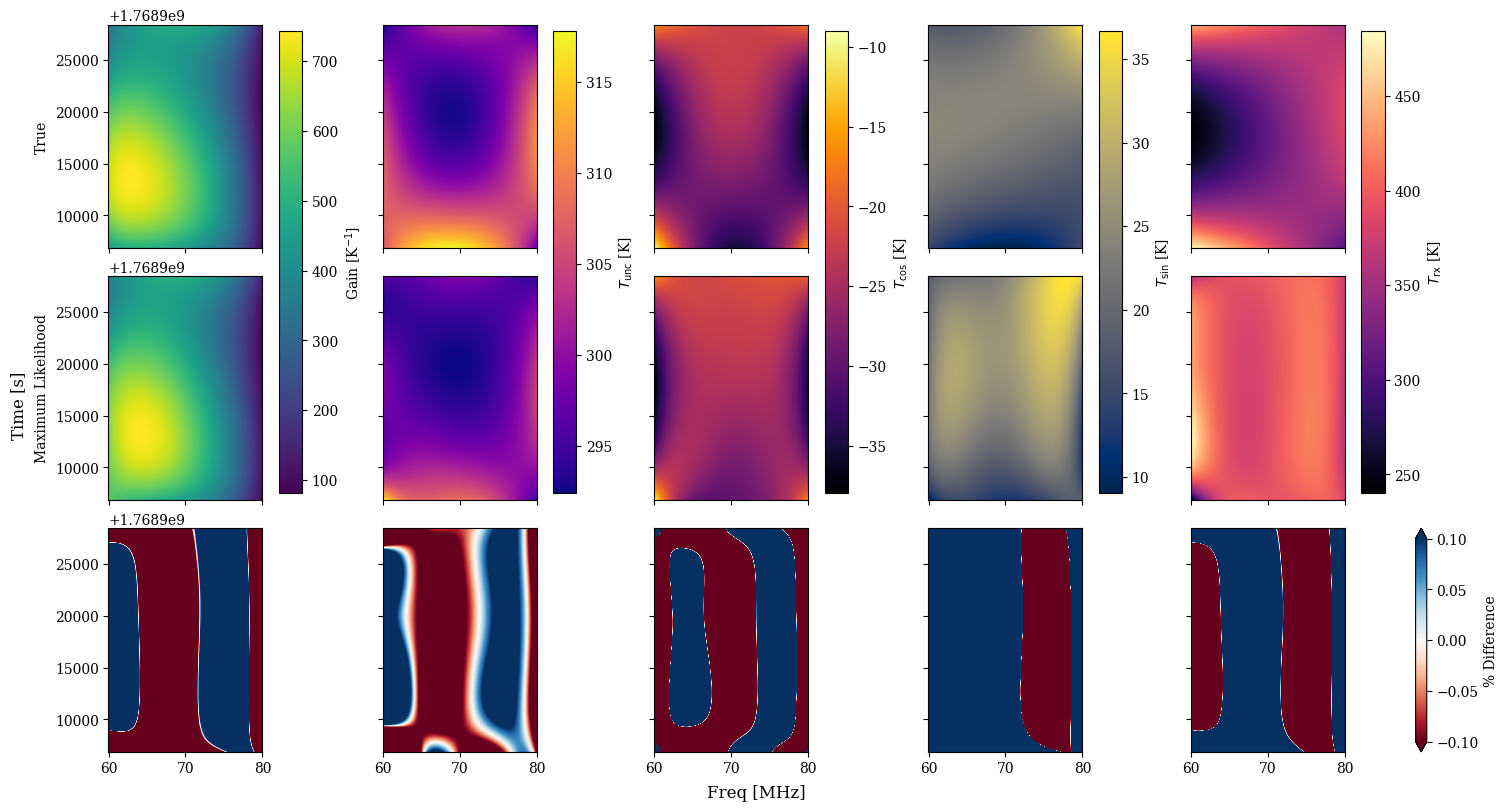

In [44]:
compare_sim_and_recontructed_all(
    true_gain_surface=gain_sim,
    gain_amplitudes=mean_gains,
    gain_basis=gains_basis,
    true_t_unc_surface=t_unc_sim,
    t_unc_amplitudes=mean_unc,
    t_unc_basis=unc_basis,
    true_t_cos_surface=t_cos_sim,
    t_cos_amplitudes=mean_cos,
    t_cos_basis=cos_basis,
    true_t_sin_surface=t_sin_sim,
    t_sin_amplitudes=mean_sin,
    t_sin_basis=sin_basis,
    true_t_rx_surface=t_rx_sim,
    t_rx_amplitudes=mean_rx,
    t_rx_basis=rx_basis,
    waterfall_shape=observation.data_waterfall.shape,
    times=observation.times,
    freqs=observation.freqs,
    residvminvmax=0.1,
    figsize=(15,8),
    # savepath='plots/calibration_map_sol.pdf'
)

In [45]:
def return_rmsd(true_surface,
                chains,
                basis_obj:BasisConstructor,):
    square_error_sum = np.zeros_like(true_surface)

    for chain in chains:
        res_surface = basis_obj.basis_matrix @ chain
        res_surface = np.reshape(res_surface, shape=true_surface.shape)
        square_error_sum += np.power((true_surface - res_surface), 2)
    rmsd = np.sqrt(square_error_sum / len(chains))
    return rmsd

def compare_sim_and_recontructed_all_from_chain(true_gain_surface,
                                                gain_chain,
                                                gain_basis:BasisConstructor,
                                                true_t_unc_surface,
                                     t_unc_chain,
                                     t_unc_basis,
                                     true_t_cos_surface,
                                     t_cos_chain,
                                     t_cos_basis:BasisConstructor,
                                     true_t_sin_surface,
                                     t_sin_chain,
                                     t_sin_basis:BasisConstructor,
                                     true_t_rx_surface,
                                     t_rx_chain,
                                     t_rx_basis:BasisConstructor,
                                     waterfall_shape,
                                     times,
                                     freqs,
                                     cmap_rec='viridis',
                                     cmap_res='RdBu',
                                     cmap_rmsd='berlin',
                                     perc_diff=False,
                                     residvminvmax=None,
                                     figsize=(10,8),
                                     gain_cmap='viridis',
                                     t_unc_cmap='plasma',
                                     t_cos_cmap='inferno',
                                     t_sin_cmap='cividis',
                                     t_rx_cmap='magma',
                                     rmsd_vmin=0,
                                     rmsd_vmax=5,
                                     savepath: str|None=None):

    fig, axes = plt.subplots(
        nrows=4,
        ncols=5,
        sharex=True,
        layout='constrained',
        figsize=figsize,
        sharey=True
        )

    freqs = np.linspace(60, 80, waterfall_shape[1])
    gain_amplitudes = np.mean(gain_chain, axis=0)
    # Gains
    rec_gain_surface = gains_basis.basis_matrix @ gain_amplitudes
    rec_gain_surface = np.reshape(
        rec_gain_surface,
        waterfall_shape
    )

    gain = axes[0,0].pcolormesh(
        freqs,
        times,
        true_gain_surface,
        cmap=gain_cmap
    )
    gain = axes[1,0].pcolormesh(
            freqs,
            times,
            rec_gain_surface,
            cmap=gain_cmap
        )

    perc_diff = 200*(true_gain_surface - rec_gain_surface) / \
        (true_gain_surface + rec_gain_surface)

    res = axes[2,0].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    gain_rmsd = return_rmsd(rec_gain_surface, gain_chain, gains_basis)
    rmsd = axes[3,0].pcolormesh(
            freqs,
            times,
            100*gain_rmsd / rec_gain_surface,
            cmap=cmap_rmsd,
            vmin=rmsd_vmin,
            vmax=rmsd_vmax
        )

    del rec_gain_surface, true_gain_surface,perc_diff, gain_rmsd

    t_unc_amplitudes = np.mean(t_unc_chain, axis=0)
    # Unc
    rec_unc_surface = unc_basis.basis_matrix @ t_unc_amplitudes
    rec_unc_surface = np.reshape(
        rec_unc_surface,
        waterfall_shape
    )

    unc = axes[0,1].pcolormesh(
        freqs,
        times,
        true_t_unc_surface,
        cmap=t_unc_cmap
    )
    unc = axes[1,1].pcolormesh(
            freqs,
            times,
            rec_unc_surface,
            cmap=t_unc_cmap
        )

    perc_diff = 200*(true_t_unc_surface - rec_unc_surface) / \
        (true_t_unc_surface + rec_unc_surface)

    res = axes[2,1].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    unc_rmsd = return_rmsd(rec_unc_surface, t_unc_chain, unc_basis)
    rmsd = axes[3,1].pcolormesh(
            freqs,
            times,
            100*unc_rmsd / rec_unc_surface,
            cmap=cmap_rmsd,
            vmin=rmsd_vmin,
            vmax=rmsd_vmax
        )

    del rec_unc_surface, true_t_unc_surface,perc_diff, unc_rmsd

    t_cos_amplitudes = np.mean(t_cos_chain, axis=0)
    # Cos
    rec_cos_surface = cos_basis.basis_matrix @ t_cos_amplitudes
    rec_cos_surface = np.reshape(
        rec_cos_surface,
        waterfall_shape
    )

    cos = axes[0,2].pcolormesh(
        freqs,
        times,
        true_t_cos_surface,
        cmap=t_cos_cmap
    )
    cos = axes[1,2].pcolormesh(
            freqs,
            times,
            rec_cos_surface,
            cmap=t_cos_cmap
        )

    perc_diff = 200*(true_t_cos_surface - rec_cos_surface) / \
        (true_t_cos_surface + rec_cos_surface)

    res = axes[2,2].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    cos_rmsd = return_rmsd(rec_cos_surface, t_cos_chain, cos_basis)
    rmsd = axes[3,2].pcolormesh(
            freqs,
            times,
            100*cos_rmsd / rec_cos_surface,
            cmap=cmap_rmsd,
            vmin=rmsd_vmin,
            vmax=rmsd_vmax
        )

    del rec_cos_surface, true_t_cos_surface,perc_diff, cos_rmsd

    # Sin
    t_sin_amplitudes = np.mean(t_sin_chain, axis=0)
    rec_sin_surface = sin_basis.basis_matrix @ t_sin_amplitudes
    rec_sin_surface = np.reshape(
        rec_sin_surface,
        waterfall_shape
    )

    sin = axes[0,3].pcolormesh(
        freqs,
        times,
        true_t_sin_surface,
        cmap=t_sin_cmap
    )
    sin = axes[1,3].pcolormesh(
            freqs,
            times,
            rec_sin_surface,
            cmap=t_sin_cmap
        )

    perc_diff = 200*(true_t_sin_surface - rec_sin_surface) / \
        (true_t_sin_surface + rec_sin_surface)

    res = axes[2,3].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    sin_rmsd = return_rmsd(rec_sin_surface, t_sin_chain, sin_basis)
    rmsd = axes[3,3].pcolormesh(
            freqs,
            times,
            100*sin_rmsd / rec_sin_surface,
            cmap=cmap_rmsd,
            vmin=rmsd_vmin,
            vmax=rmsd_vmax
        )
    del rec_sin_surface, true_t_sin_surface,perc_diff, sin_rmsd

    # Rx
    t_rx_amplitudes = np.mean(t_rx_chain, axis=0)
    rec_rx_surface = rx_basis.basis_matrix @ t_rx_amplitudes
    rec_rx_surface = np.reshape(
        rec_rx_surface,
        waterfall_shape
    )

    rx = axes[0,4].pcolormesh(
        freqs,
        times,
        true_t_rx_surface,
        cmap=t_rx_cmap
    )
    rx = axes[1,4].pcolormesh(
            freqs,
            times,
            rec_rx_surface,
            cmap=t_rx_cmap
        )

    perc_diff = 200*(true_t_rx_surface - rec_rx_surface) / \
        (true_t_rx_surface + rec_rx_surface)

    res = axes[2,4].pcolormesh(
            freqs,
            times,
            perc_diff,
            cmap=cmap_res,
            vmin=-residvminvmax,
            vmax=residvminvmax
        )

    rx_rmsd = return_rmsd(rec_rx_surface, t_rx_chain, rx_basis)
    rmsd = axes[3,4].pcolormesh(
            freqs,
            times,
            100*rx_rmsd / rec_rx_surface,
            cmap=cmap_rmsd,
            vmin=rmsd_vmin,
            vmax=rmsd_vmax
        )
    del rec_rx_surface, true_t_rx_surface,perc_diff, rx_rmsd

    axes[0,0].set_ylabel('True')
    axes[1,0].set_ylabel('Maximum Likelihood')

    fig.colorbar(res,
                 ax=[axes[2,i] for i in range(5)],
                 label='Difference [%]',
                 extend='both')
    
    fig.colorbar(
            rmsd,
            ax=[axes[3,i] for i in range(5)],
            label='Sample RMSD / Sample Mean [%]',
            extend='both'
        )

    fig.colorbar(
        unc,
        ax=[axes[i,1] for i in range(2)],
        label=r'$T_{\rm unc}$ [K]'
    )
    fig.colorbar(
            cos,
            ax=[axes[i,2] for i in range(2)],
            label=r'$T_{\rm cos}$ [K]'
        )
    fig.colorbar(
            sin,
            ax=[axes[i,3] for i in range(2)],
            label=r'$T_{\rm sin}$ [K]'
        )
    fig.colorbar(
            rx,
            ax=[axes[i,4] for i in range(2)],
            label=r'$T_{\rm rx}$ [K]'
        )
    fig.colorbar(
            gain,
            ax=[axes[i,0] for i in range(2)],
            label=r'Gain [K$^{-1}$]'
        )


    fig.supxlabel(r'Freq [MHz]')
    fig.supylabel(r'Time [s]')
    if savepath is not None:
        fig.savefig(fname=savepath)
    plt.show()
    

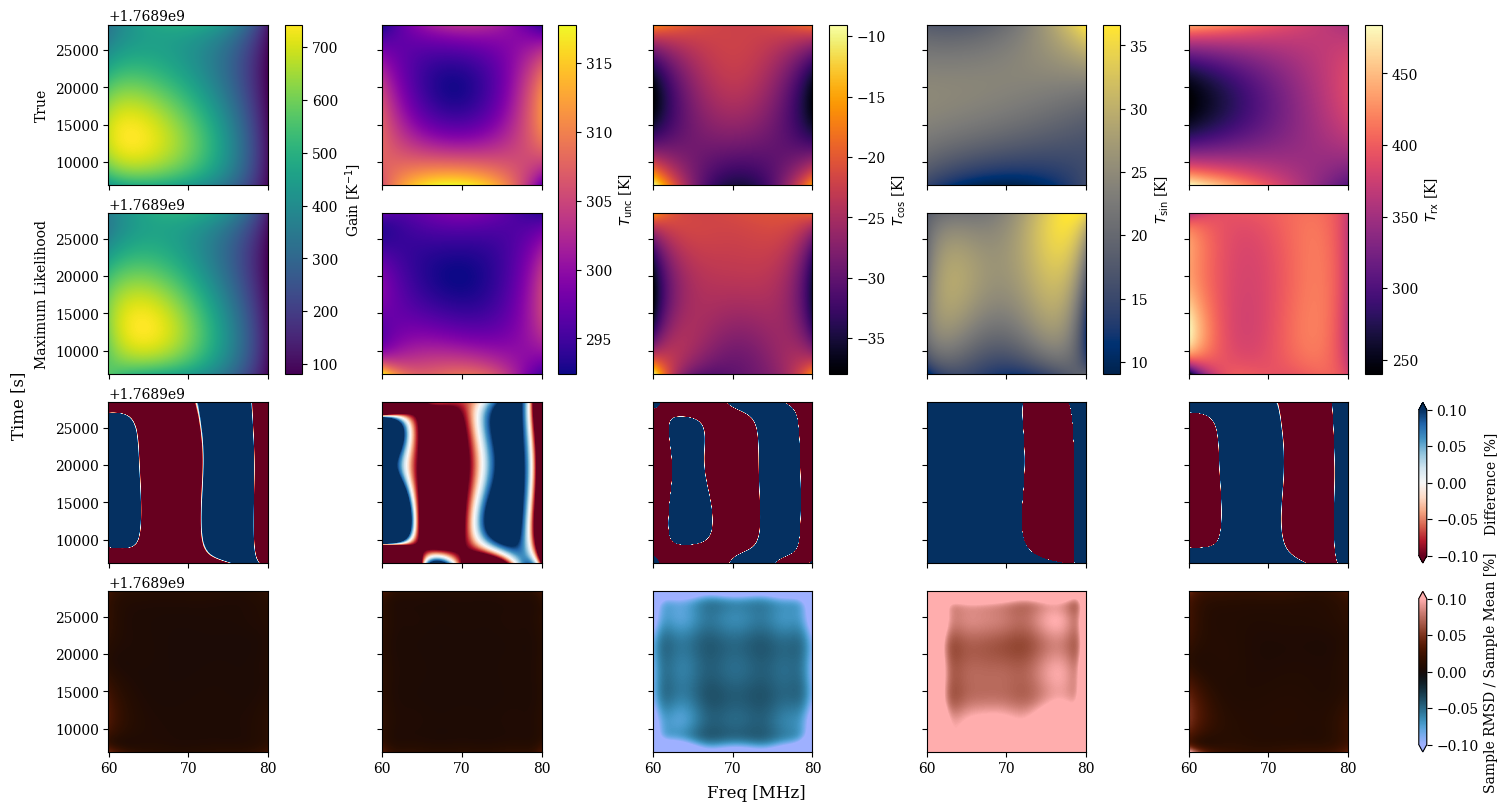

In [46]:
compare_sim_and_recontructed_all_from_chain(
    true_gain_surface=gain_sim,
    gain_chain=param_dict['all_p_gain'],
    gain_basis=gains_basis,
    true_t_unc_surface=t_unc_sim,
    t_unc_chain=t_unc_chains,
    t_unc_basis=unc_basis,
    true_t_cos_surface=t_cos_sim,
    t_cos_chain=t_cos_chains,
    t_cos_basis=cos_basis,
    true_t_sin_surface=t_sin_sim,
    t_sin_chain=t_sin_chains,
    t_sin_basis=sin_basis,
    true_t_rx_surface=t_rx_sim,
    t_rx_chain=t_rx_chains,
    t_rx_basis=rx_basis,
    waterfall_shape=observation.data_waterfall.shape,
    times=observation.times,
    freqs=observation.freqs,
    residvminvmax=0.1,
    figsize=(15,8),
    rmsd_vmin=-0.1,
    rmsd_vmax=0.1,
    # savepath='plots/calibration_map_sol.pdf'
)

# Plot 1D Distribution


In [47]:
def plot_1d_spectra(
        true_surface,
        basis:BasisConstructor,
        chains,
        freqs,
        waterfall_shape,
        ylabel,
        color='green',
):
    quantiles = [0.5-(0.97/2),
                 0.5-(0.68/2),
                 0.5,
                 0.5+(0.97/2),
                 0.5+(0.68/2)]
    # Get the quantiled from chains
    param_quantile_list = [
        np.quantile(chains,
                    q,
                    axis=0) for q in quantiles
    ]
    mean_chain = np.mean(chains, axis=0)

    true_spectra = np.mean(true_surface, axis=0)
    del true_surface
    def reproduce_spectra(amps):
        rec = basis.basis_matrix @ amps
        rec = np.reshape(rec, waterfall_shape)
        return rec.mean(axis=0)


    mean_chain_spectra = reproduce_spectra(mean_chain)
    median_chain_spectra = reproduce_spectra(np.quantile(chains,
                                                         0.5,
                                                         axis=0))

    one_sigma_bounds = [reproduce_spectra(np.quantile(chains,
                                                         0.5-(0.68/2),
                                                         axis=0)),
                        reproduce_spectra(np.quantile(chains,
                                                      0.5+(0.68/2),
                                                      axis=0)),]


    reproduced_gains = np.array(
        [reproduce_spectra(chain_i) for chain_i in chains]
        )

    mean_gain = np.mean(reproduced_gains, axis=0)
    median_gain = np.median(reproduced_gains, axis=0)

    sigma_bounds = [
        np.quantile(reproduced_gains, 0.5-(0.68/2), axis=0),
        np.quantile(reproduced_gains, 0.5+(0.68/2), axis=0)
    ]
    three_sigma_bounds = [
            np.quantile(reproduced_gains, 0.5-(0.997/2), axis=0),
            np.quantile(reproduced_gains, 0.5+(0.997/2), axis=0)
        ]

    plt.plot(freqs, true_spectra, label='Truth')
    plt.plot(freqs, mean_gain, label='Mean')
    plt.plot(freqs, median_gain, label='Median')
    plt.fill_between(freqs, sigma_bounds[0], sigma_bounds[-1],
                     color=color, alpha=0.25)
    
    plt.fill_between(freqs, three_sigma_bounds[0], three_sigma_bounds[-1],
                     color=color, alpha=0.25)
    
    plt.show()
    plt.plot(freqs, mean_gain-true_spectra, label='Mean')
    plt.plot(freqs, median_gain-true_spectra, label='Median')
    plt.fill_between(freqs, sigma_bounds[0]-true_spectra, 
                     sigma_bounds[-1]-true_spectra,
                         color=color, alpha=0.25)
    plt.fill_between(freqs, three_sigma_bounds[0]-true_spectra, 
                         three_sigma_bounds[-1]-true_spectra,
                             color=color, alpha=0.25)
    plt.legend()
    plt.show()


    

In [48]:
# plot_1d_spectra(gain_sim,
#                 basis=gains_basis,
#                 chains=param_dict['all_p_gain'],
#                 freqs=observation.freqs,
#                 waterfall_shape=observation.data_waterfall.shape,
#                 ylabel='')
# plot_1d_spectra(t_rx_sim,
#                 basis=rx_basis,
#                 chains=t_rx_chains,
#                 freqs=observation.freqs,
#                 waterfall_shape=observation.data_waterfall.shape,
#                 ylabel=r'$T_{\rm rx}$',
#                 color='red')
# plot_1d_spectra(t_cos_sim,
#                 basis=cos_basis,
#                 chains=t_cos_chains,
#                 freqs=observation.freqs,
#                 waterfall_shape=observation.data_waterfall.shape,
#                 ylabel=r'$T_{\rm cos}$',
#                 color='blue')
# plot_1d_spectra(t_sin_sim,
#                 basis=sin_basis,
#                 chains=t_sin_chains,
#                 freqs=observation.freqs,
#                 waterfall_shape=observation.data_waterfall.shape,
#                 ylabel=r'$T_{\rm sin}$',
#                 color='orange')
# plot_1d_spectra(t_unc_sim,
#                 basis=unc_basis,
#                 chains=t_unc_chains,
#                 freqs=observation.freqs,
#                 waterfall_shape=observation.data_waterfall.shape,
#                 ylabel=r'$T_{\rm sin}$',
#                 color='purple')

In [49]:
def plot_all_1d_cal_spectra(
        gain_chain,
        unc_chain,
        cos_chain,
        sin_chain,
        rx_chain,
        gain_basis,
        unc_basis,
        cos_basis,
        sin_basis,
        rx_basis,
        true_gains,
        true_unc,
        true_cos,
        true_sin,
        true_rx,
        waterfall_shape,
        freqs,
        c_gain='green',
        c_unc='purple',
        c_cos='red',
        c_sin='blue',
        c_rx='orangered',
        c_true='black',
        saveplot=None,
        figsize=(15,10),
        alpha=0.25,
):
    fig, axes = plt.subplots(
        nrows=2,
        ncols=5,
        layout='constrained',
        figsize=figsize,
        sharex=True,
    )

    def plot_comp(full_ax,
                  resid_ax,
                  chain,
                  basis,
                  true_spec,
                  color,
                  alpha):
        def reproduce_spectra(amps):
                rec = basis.basis_matrix @ amps
                rec = np.reshape(rec, waterfall_shape)
                return rec.mean(axis=0)
        reproduced_spectra = np.array(
                [reproduce_spectra(chain_i) for chain_i in chain]
                )
        true_spec = true_spec.mean(axis=0) # convert surface to 1D

        med_spectra = np.quantile(reproduced_spectra,
                                  0.5, axis=0)
        sigma_bounds = [
                np.quantile(reproduced_spectra, 0.5-(0.68/2), axis=0),
                np.quantile(reproduced_spectra, 0.5+(0.68/2), axis=0)
            ]
        three_sigma_bounds = [
                    np.quantile(reproduced_spectra, 0.5-(0.997/2), axis=0),
                    np.quantile(reproduced_spectra, 0.5+(0.997/2), axis=0)
                ]
        

        full_ax.plot(freqs, true_spec, c=c_true, label='True')
        full_ax.plot(freqs, med_spectra, c=color, label='Max Prob.')
        full_ax.fill_between(freqs, sigma_bounds[0], sigma_bounds[-1],
                             color=color, alpha=2*alpha, label=r'$1\,\sigma$')
        full_ax.fill_between(freqs, three_sigma_bounds[0], three_sigma_bounds[-1],
                                     color=color, alpha=alpha, label=r'$3\,\sigma$')

        resid_ax.plot(freqs, med_spectra - true_spec, c=color)
        resid_ax.fill_between(freqs, sigma_bounds[0]-true_spec,
                              sigma_bounds[-1]-true_spec,
                                     color=color, alpha=2*alpha)
        resid_ax.fill_between(freqs, three_sigma_bounds[0]-true_spec,
                              three_sigma_bounds[-1]-true_spec,
                                             color=color, alpha=alpha)
        resid_ax.plot(freqs, np.zeros_like(freqs), ls='--', c='black')
        pass


    plot_comp(axes[0,0], axes[1,0], chain=gain_chain, basis=gain_basis,
              true_spec=true_gains, color=c_gain, alpha=alpha)
    plot_comp(axes[0,1], axes[1,1], chain=unc_chain, basis=unc_basis,
                  true_spec=true_unc, color=c_unc, alpha=alpha)
    plot_comp(axes[0,2], axes[1,2], chain=cos_chain, basis=cos_basis,
                  true_spec=true_cos, color=c_cos, alpha=alpha)
    plot_comp(axes[0,3], axes[1,3], chain=sin_chain, basis=sin_basis,
                  true_spec=true_sin, color=c_sin, alpha=alpha)
    plot_comp(axes[0,4], axes[1,4], chain=rx_chain, basis=rx_basis,
                  true_spec=true_rx, color=c_rx, alpha=alpha)

    fig.supxlabel(r'Frequency [MHz]')

    axes[0,0].set_ylabel(r'Gain [K$^{-1}$]')
    axes[0,1].set_ylabel(r'$T_{\rm unc}$ [K]')
    axes[0,2].set_ylabel(r'$T_{\rm cos}$ [K]')
    axes[0,3].set_ylabel(r'$T_{\rm sin}$ [K]')
    axes[0,4].set_ylabel(r'$T_{\rm rx}$ [K]')
    axes[1,0].set_ylabel(r'Residual [K$^{-1}$]')
    axes[1,1].set_ylabel(r'Residual [K]')
    axes[0,0].legend(frameon=False)
    if saveplot is not None:
        fig.savefig(saveplot)
    plt.show()



        

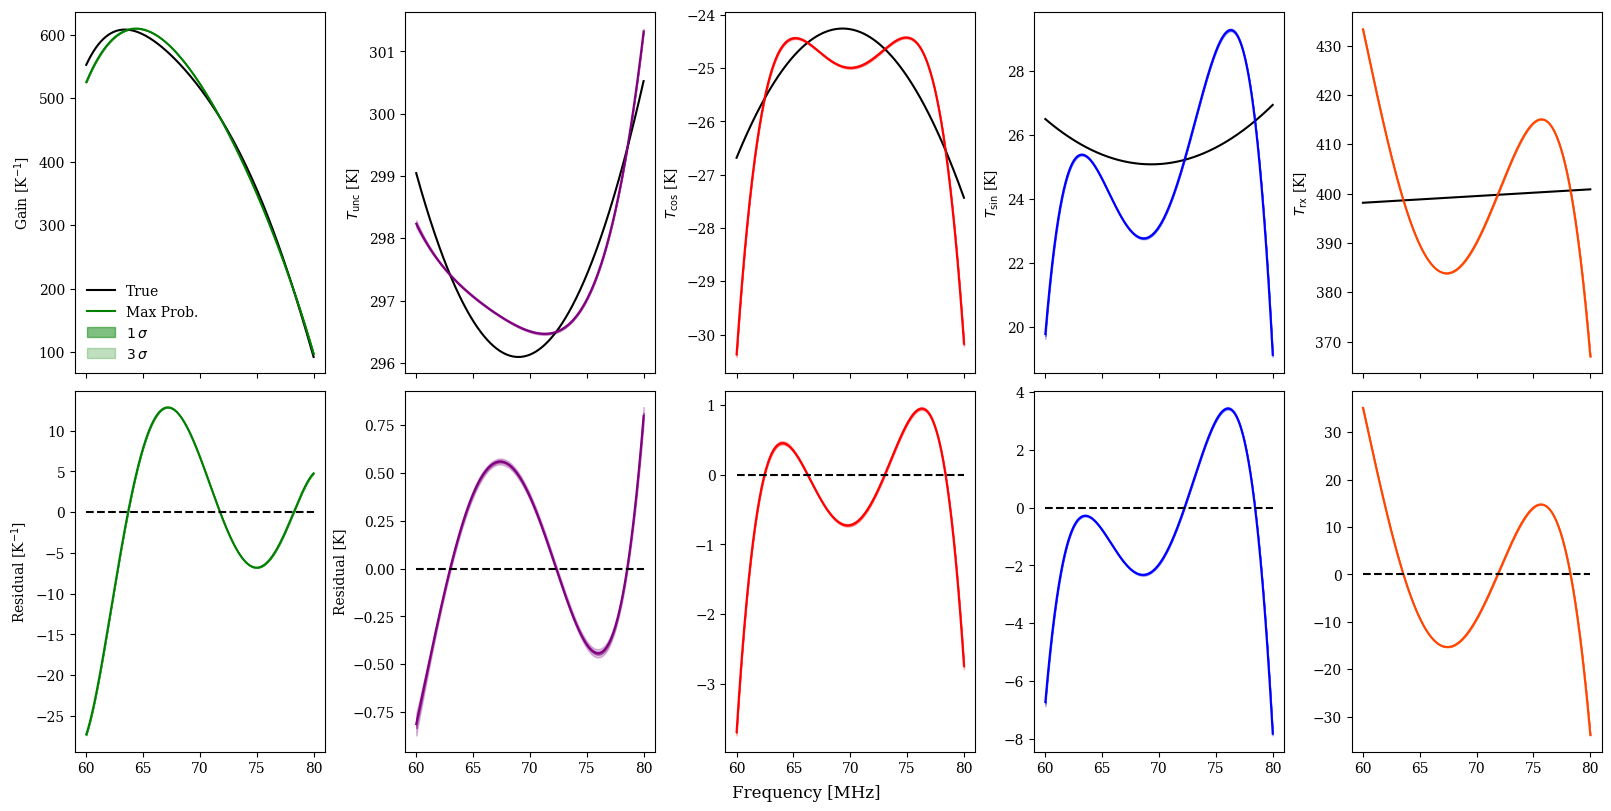

In [50]:
plot_all_1d_cal_spectra(gain_chain=param_dict['all_p_gain'],
                        unc_chain=t_unc_chains,
                        cos_chain=t_cos_chains,
                        sin_chain=t_sin_chains,
                        rx_chain=t_rx_chains,
                        gain_basis=gains_basis,
                        unc_basis=unc_basis,
                        cos_basis=cos_basis,
                        sin_basis=sin_basis,
                        rx_basis=rx_basis,
                        true_gains=gain_sim,
                        true_unc=t_unc_sim,
                        true_cos=t_cos_sim,
                        true_sin=t_sin_sim,
                        true_rx=t_rx_sim,
                        waterfall_shape=observation.data_waterfall.shape,
                        freqs=observation.freqs,
                        figsize=(16,8),
                        saveplot='../plots/case3_1d_recovery.pdf')

### Plotting for the spectral, time static case.

Create plots of the various 

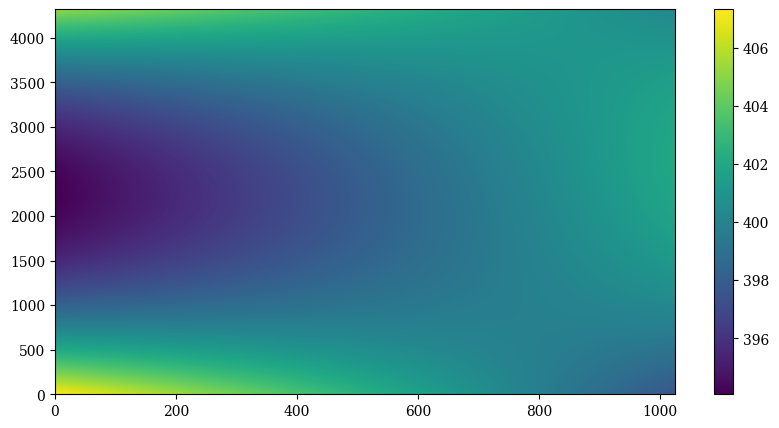

In [51]:
plt.pcolormesh(t_rx_sim)
plt.colorbar()
plt.show()

# Plotting Chains and Auto Correlation

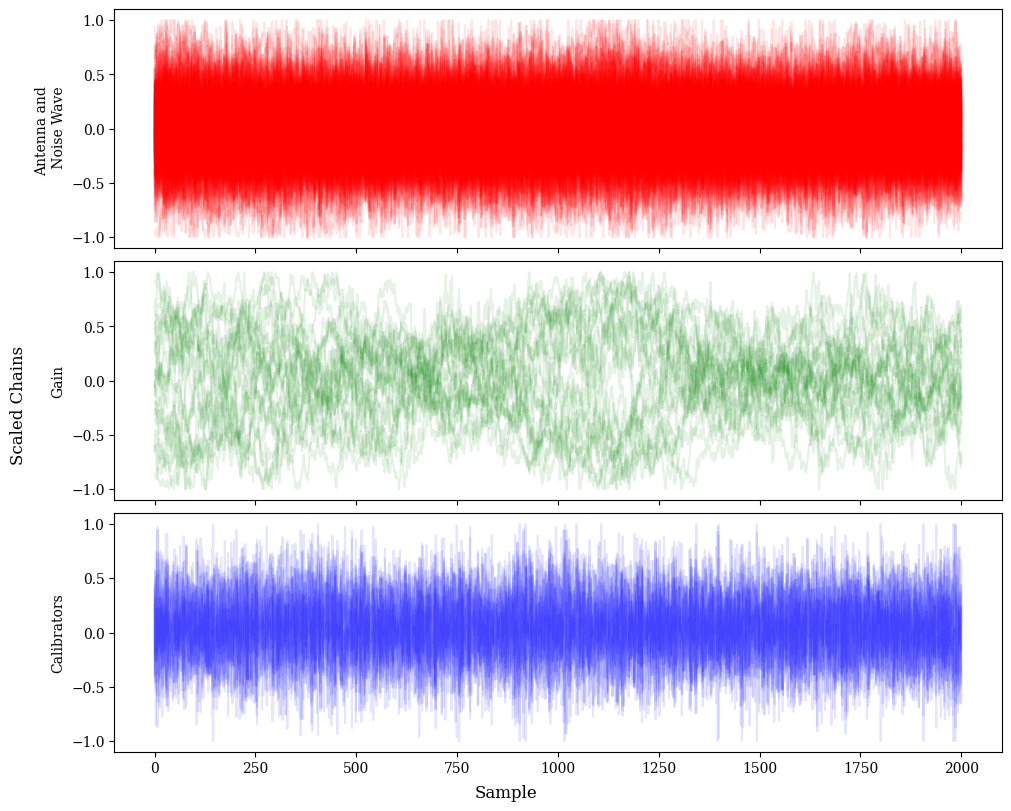

In [52]:
def plot_chains(ant_nw_chains,
                cal_chains,
                gain_chains,
                c_ant_nw='red',
                c_cal='blue',
                c_gain='green',
                alpha=0.25,
                figsize=(10,8),
                autocorrelation=False):
    """ 
    Plot chains
    """
    n_samps = len(ant_nw_chains[:,0])
    samples = np.arange(n_samps)

    fig, (ax1, ax2, ax3) = plt.subplots(
        nrows=3,
        sharex=True,
        layout='constrained',
        figsize=figsize,
    )

    def _plotchain(axis, chain, c, auto_axis=None):
        chain_min, chain_max = np.min(chain), np.max(chain)
        scaled_chain = 2.0 * (chain - chain_min) / (chain_max - chain_min) - 1.0
        axis.plot(samples, scaled_chain, c=c, alpha=alpha)


    
    # ant_nw
    n_params = len(ant_nw_chains[0])
    for i in range(n_params):

        _plotchain(ax1, ant_nw_chains[:,i],c_ant_nw)

    # gains
    n_params = len(gain_chains[0])
    for i in range(n_params):
        _plotchain(ax2, gain_chains[:,i], c_gain)
    # cal
    n_params = len(cal_chains[0])
    for i in range(n_params):
        _plotchain(ax3, cal_chains[:,i], c_cal)

    ###
    ax1.set_ylabel('Antenna and \n Noise Wave')
    ax2.set_ylabel('Gain')
    ax3.set_ylabel('Calibrators')
    fig.supxlabel('Sample')
    fig.supylabel('Scaled Chains')
    plt.show()

plot_chains(ant_nw_chains=param_dict['all_p_ant_nw'],
            gain_chains=param_dict['all_p_gain'],
            cal_chains=param_dict['all_p_cal_src'],
            alpha=0.1)

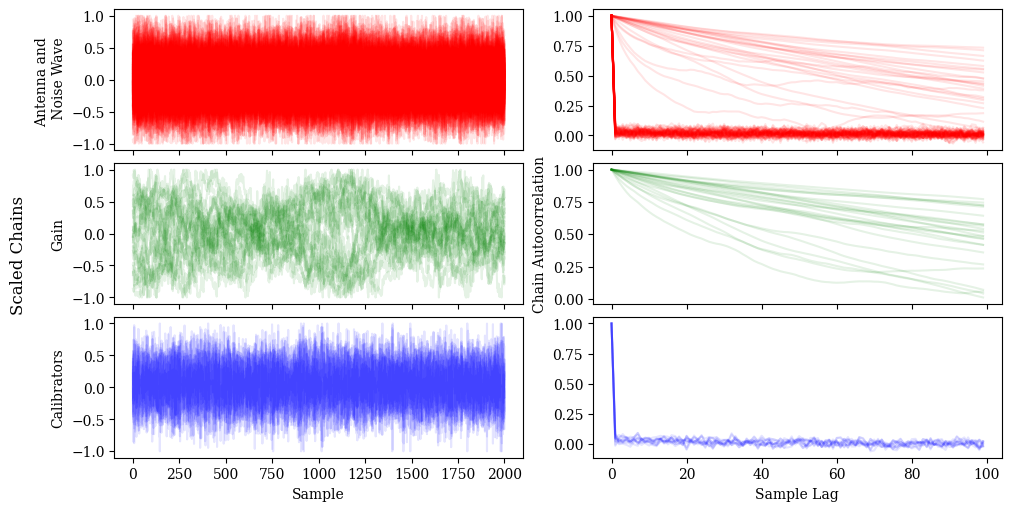

In [53]:
def plot_chains_and_auto_correlation(ant_nw_chains,
                                     cal_chains,
                                     gain_chains,
                                     c_ant_nw='red',
                                     c_cal='blue',
                                     c_gain='green',
                                     alpha=0.25,
                                     figsize=(10,8),
                                     auto_lim=50):
    """ 
    Plot chains
    """
    n_samps = len(ant_nw_chains[:,0])
    samples = np.arange(n_samps)

    fig, axes = plt.subplots(
        nrows=3,
        ncols=2,
        sharex='col',
        layout='constrained',
        figsize=figsize,
    )

    def _plotchain(axis, chain, c, auto_axis):
        chain_min, chain_max = np.min(chain), np.max(chain)
        scaled_chain = 2.0 * (chain - chain_min) / (chain_max - chain_min) - 1.0
        axis.plot(samples, scaled_chain, c=c, alpha=alpha)

        auto_chain = np.correlate((chain / chain.mean())-1, (chain / chain.mean())-1, mode='full')
        auto_chain = auto_chain[auto_chain.size // 2:]
        auto_axis.plot(auto_chain[:auto_lim] / np.max(auto_chain[:auto_lim]), c=c, alpha=alpha)


    
    # ant_nw
    n_params = len(ant_nw_chains[0])
    for i in range(n_params):

        _plotchain(axes[0,0], ant_nw_chains[:,i],c_ant_nw, axes[0,1])

    # gains
    n_params = len(gain_chains[0])
    for i in range(n_params):
        _plotchain(axes[1,0], gain_chains[:,i], c_gain, axes[1,1])
    # cal
    n_params = len(cal_chains[0])
    for i in range(n_params):
        _plotchain(axes[2,0], cal_chains[:,i], c_cal, axes[2,1])

    ###
    axes[0,0].set_ylabel('Antenna and \n Noise Wave')
    axes[1,0].set_ylabel('Gain')
    axes[2,0].set_ylabel('Calibrators')
    fig.supylabel('Scaled Chains')

    axes[2,0].set_xlabel('Sample')
    axes[2,1].set_xlabel('Sample Lag')

    auto_axes = [axes[i,1] for i in range(3)]
    axes[1,1].set_ylabel('Chain Autocorrelation')

    plt.show()

plot_chains_and_auto_correlation(ant_nw_chains=param_dict['all_p_ant_nw'],
            gain_chains=param_dict['all_p_gain'],
            cal_chains=param_dict['all_p_cal_src'],
            alpha=0.1,
            auto_lim=100,
            figsize=(10,5))

# Source Recovery

In [54]:
def source_recovery(data_waterfall,
                    times,
                    freqs,
                    states_array,
                    reflection_obj:ReflectionReader,
                    gain_coeffs,
                    U_gain,
                    nw_coeffs,
                    X_nw,
                    source='antenna'):
    gains = U_gain @ gain_coeffs
    nw_contributions = X_nw @ nw_coeffs

    gains = np.reshape(gains, data_waterfall.shape)
    nw_contributions = np.reshape(nw_contributions, data_waterfall.shape) # includes the reflections

    scaled_data = (data_waterfall / gains) - nw_contributions # K weighted by src temp

    # select data
    source_mask = (states_array == source)
    source_data = scaled_data[source_mask]
    source_times = times[source_mask]

    cs_src = reflection_obj.cs_dict[source]

    t_src = source_data / cs_src

    return t_src, source_times, freqs

    

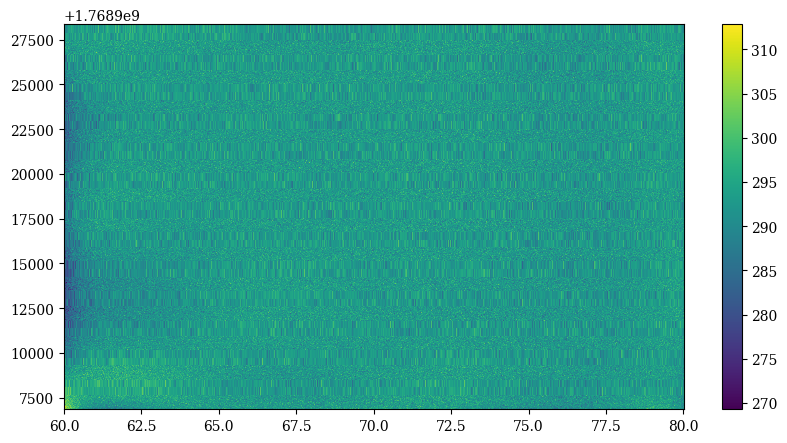

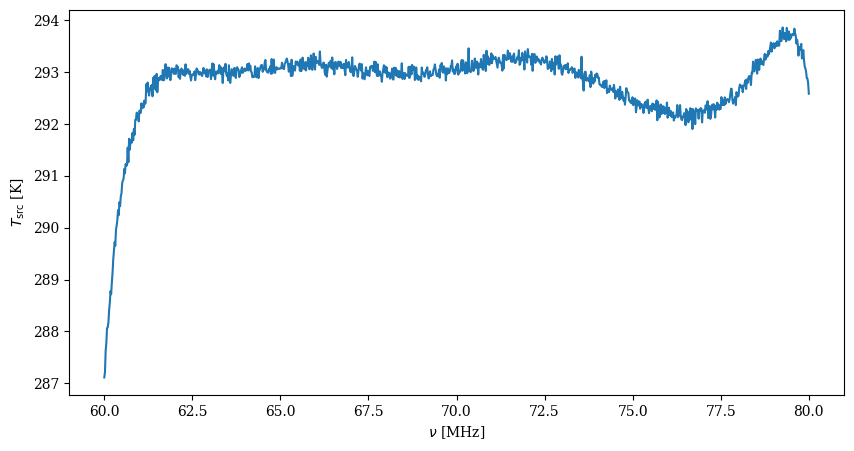

292.8071714706387
0.7405848129937328


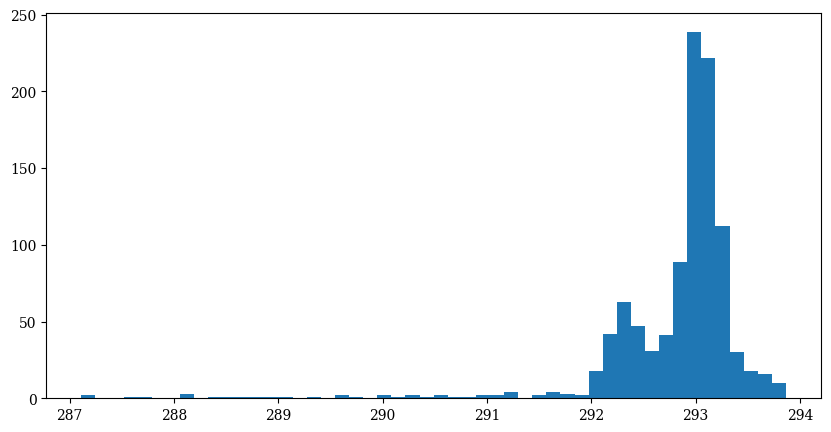

In [55]:
# Recover only source temperatures

gain_coeffs = np.median(param_dict['all_p_gain'],axis=0)
nw_coeffs = np.median(param_dict['all_p_ant_nw'], axis=0)[ant_noise_wave_slice_dict['noise_wave']]

source_temperatures, source_times, source_freqs = source_recovery(observation.data_waterfall,
                                                                  observation.times,
                                                                  observation.freqs,
                                                                  states_array=observation.states_array,
                                                                  reflection_obj=reflections,
                                                                  gain_coeffs=gain_coeffs,
                                                                  U_gain=U_gain,
                                                                  nw_coeffs=nw_coeffs,
                                                                  X_nw = X_noise_wave,
                                                                  source='antenna')


plt.pcolormesh(source_freqs,
               source_times,
               source_temperatures)
plt.colorbar()
plt.show()

plt.plot(source_freqs, source_temperatures.mean(axis=0))
plt.ylabel(r'$T_{\rm src}$ [K]')
plt.xlabel(r'$\nu$ [MHz]')
plt.show()

print(np.mean(source_temperatures.mean(axis=0)))
print(np.std(source_temperatures.mean(axis=0)))

plt.hist(source_temperatures.mean(axis=0), bins=50)
plt.show()